In [1]:
import torch.nn as nn
from pathlib import Path
import numpy as np

import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from ML_Base import XANESVisualizer, XANESDataLoader, XANESPipeline
from Wrappers import TorchWrapper
os.chdir(curdir)

In [2]:
class ReshapeWrapper(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, x):
        return x.unsqueeze(self.dim)

        
# 2. Обновленная архитектура Torch
class XANES_CNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            ReshapeWrapper(1),             # Теперь это корректный nn.Module [Batch, 1, Seq]
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=5, padding='same'), nn.GELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=5, padding='same'), nn.GELU(),
            nn.AdaptiveAvgPool1d(10),       # Сжимаем временную/энергетическую ось до 10
            nn.Flatten(),
            nn.Linear(32 * 10, 64), nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x)

In [3]:
# Пути к сценарию 1A
paths_JanisLike = {
                    'train_x': Path('../processed_data/DataSets/JanisLike_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/JanisLike_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/JanisLike_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/JanisLike_Test_y.npz'),
                  }

# Пути к сценарию 1B
paths_NotJanisLike = {
                    'train_x': Path('../processed_data/DataSets/NotJanisLike_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/NotJanisLike_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/NotJanisLike_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/NotJanisLike_Test_y.npz'),
                  }

# Пути к сценарию 2A
paths_No_Strict = {
                    'train_x': Path('../processed_data/DataSets/No_Strict2A_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/No_Strict2A_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/No_Strict2A_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/No_Strict2A_Test_y.npz'),
                  }


# Пути к сценарию 2B
paths_Lauvian = {
                    'train_x': Path('../processed_data/DataSets/Lauvian2B_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/Lauvian2B_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/Lauvian2B_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/Lauvian2B_Test_y.npz'),
                }

In [4]:
# Используем стандартизацию данных или нет.
STAND = True
IN_DIM=141 # Размер входного спектра.
E_GRID = np.arange(-10,60.1,0.5) # Сетка энергий для спектра

In [5]:
params = {
    # --- Основные параметры ---
    'epochs':480,
    'batch_size':256,
    'lr':1e-3,
    'weight_decay': 0, #0, #1e-3,
    'loss_params':{'alpha':1.0, 'beta':1.0, 'gamma':0.}, # MSE (0,1,0)-MAE, (0,0,1)-Mape
    'T_0':80,
    'T_mult':2,
    'eta_min':1e-6,
    'patience':160,
    'min_delta':0,
}

### Cценарий1A (JanisLike) (возможна утечка данных)


🚀 Моделирование CN1...


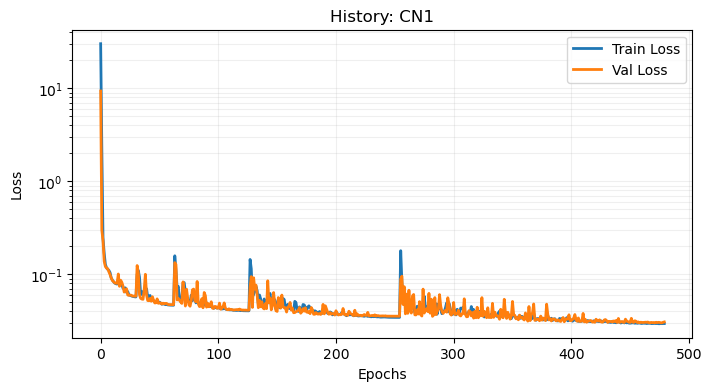

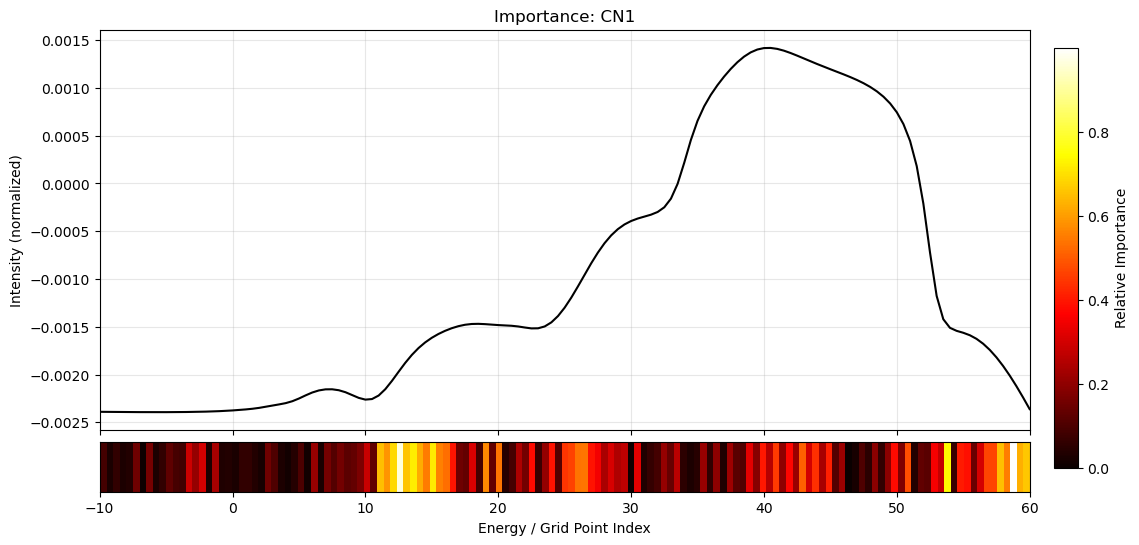

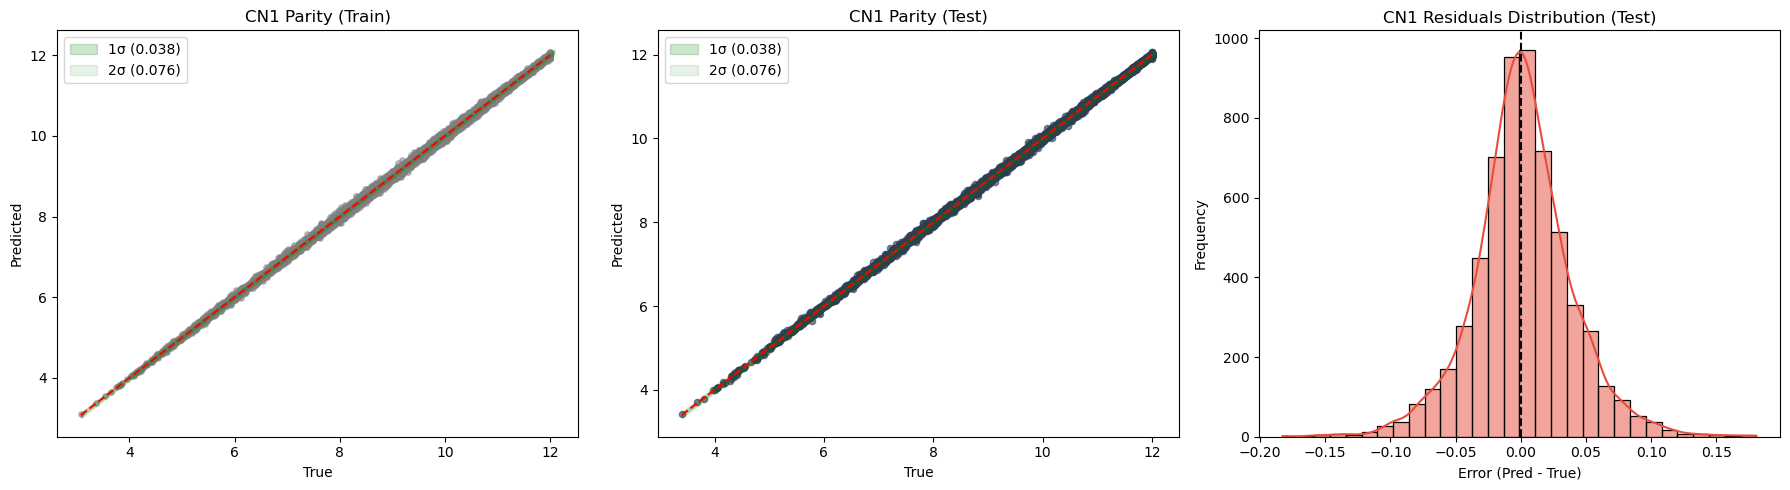


🚀 Моделирование CN2...


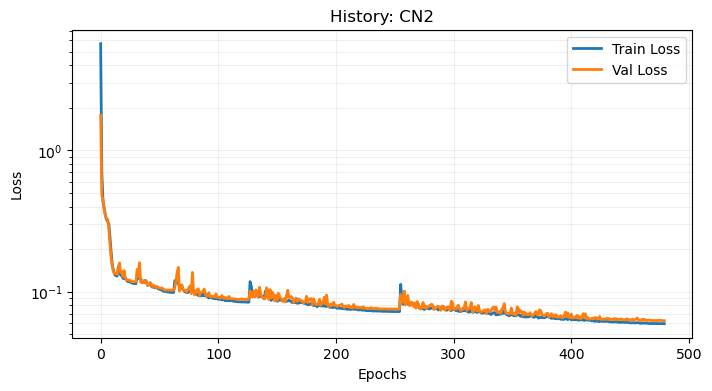

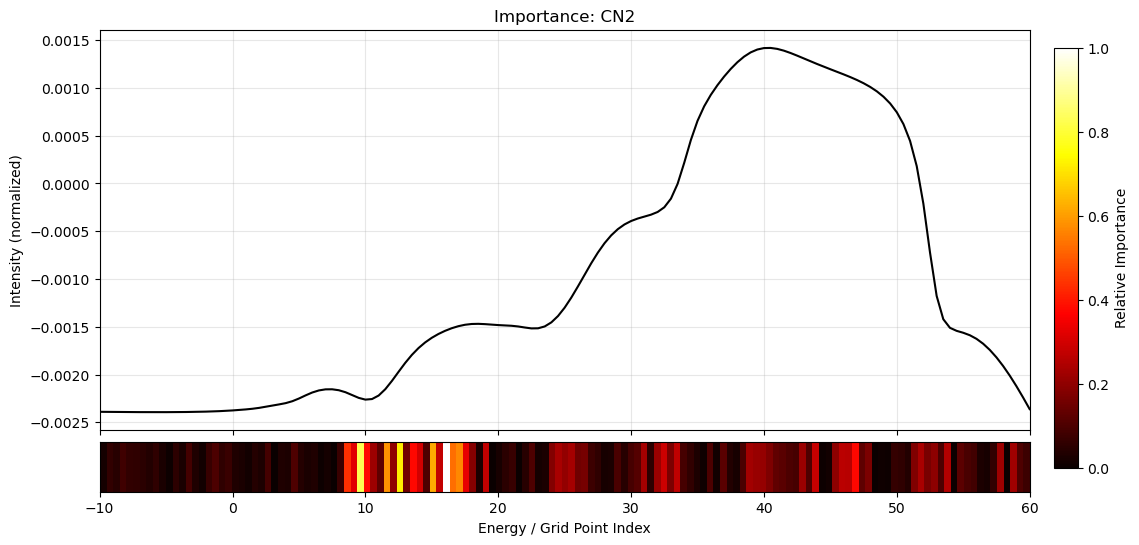

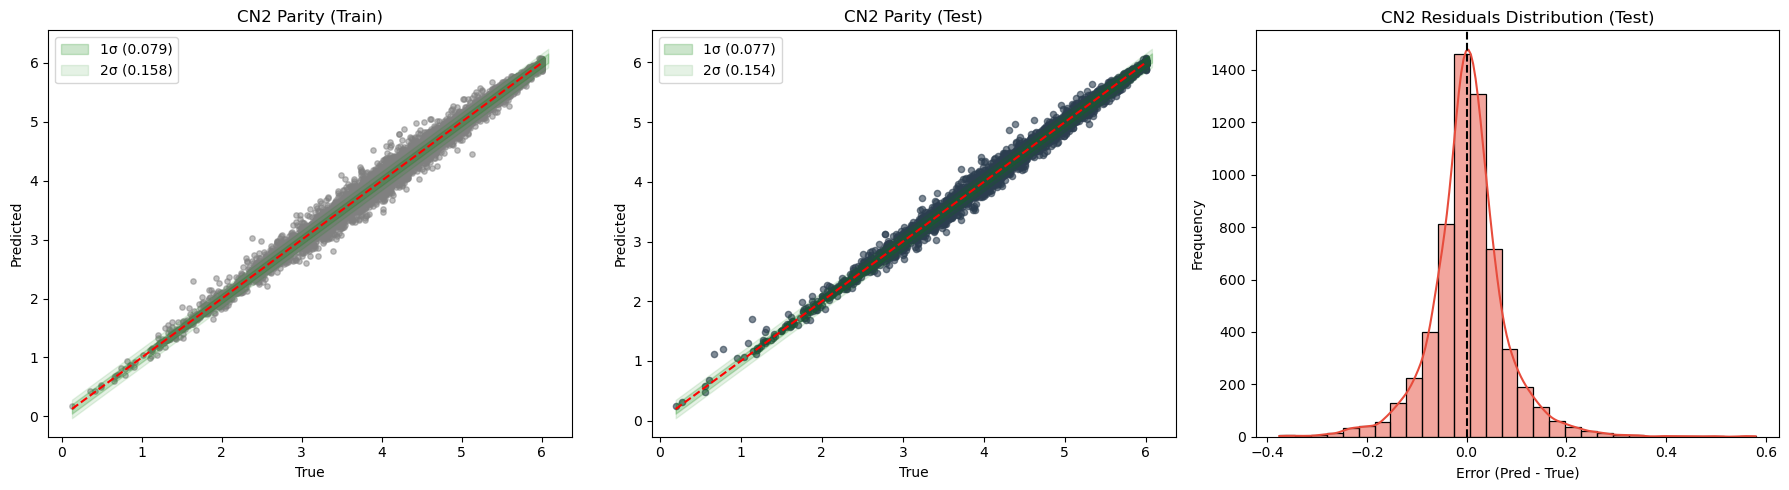


🚀 Моделирование CN3...


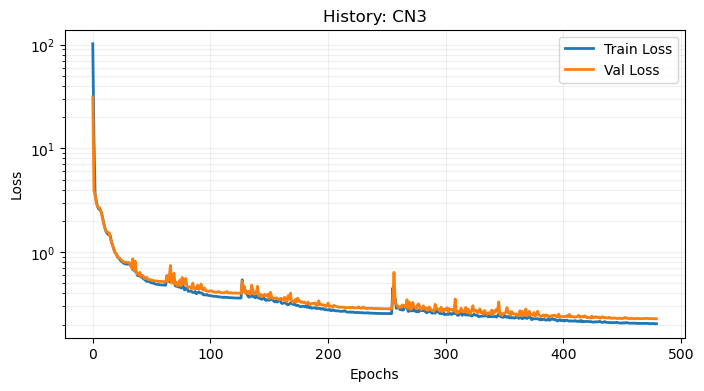

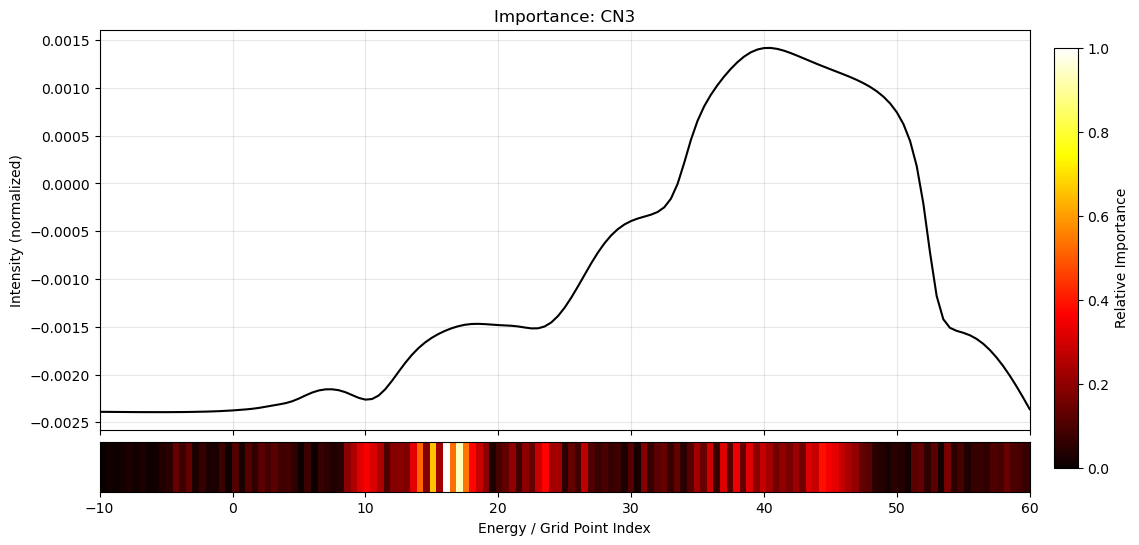

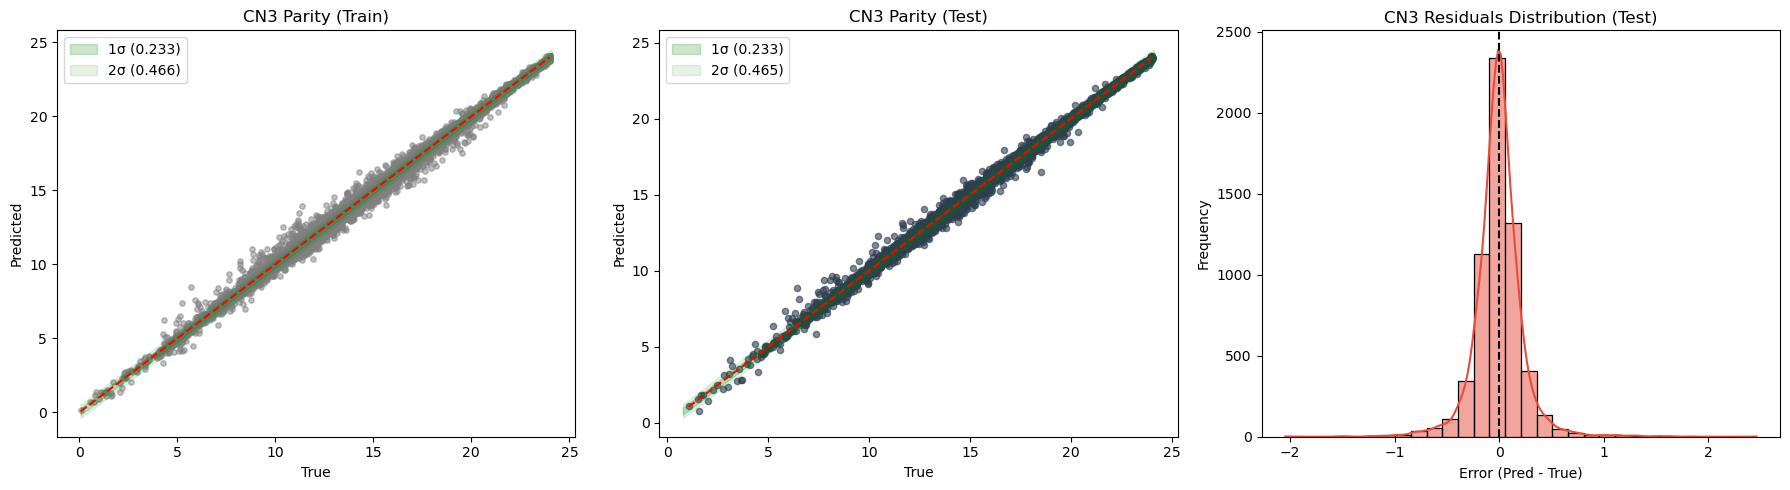


🚀 Моделирование CN4...


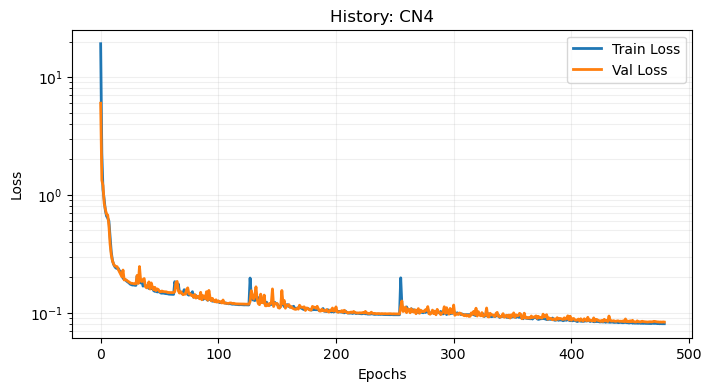

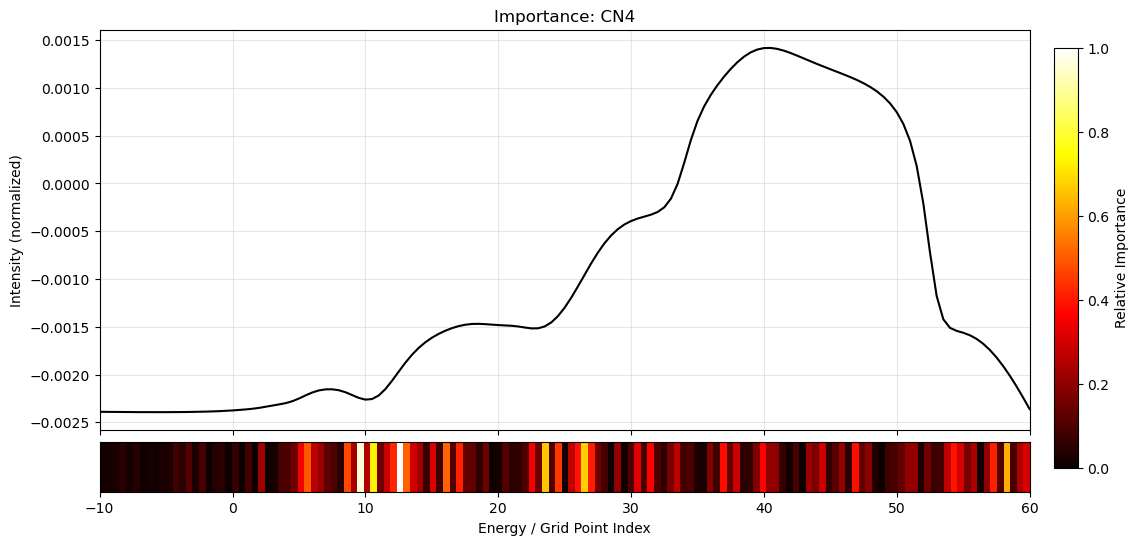

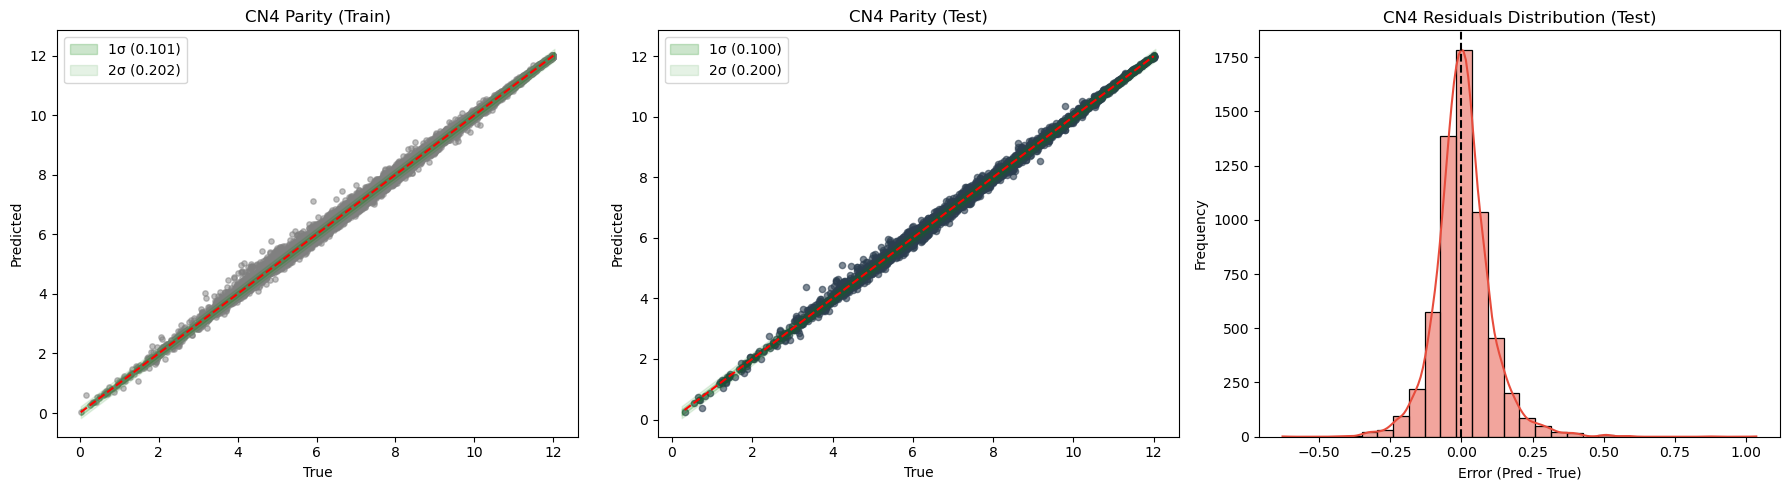


🚀 Моделирование CN5...


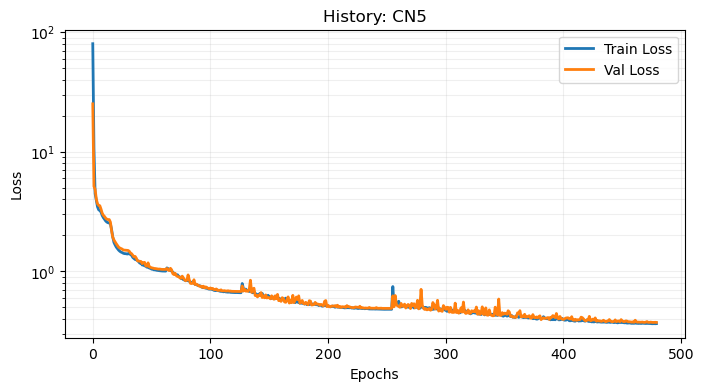

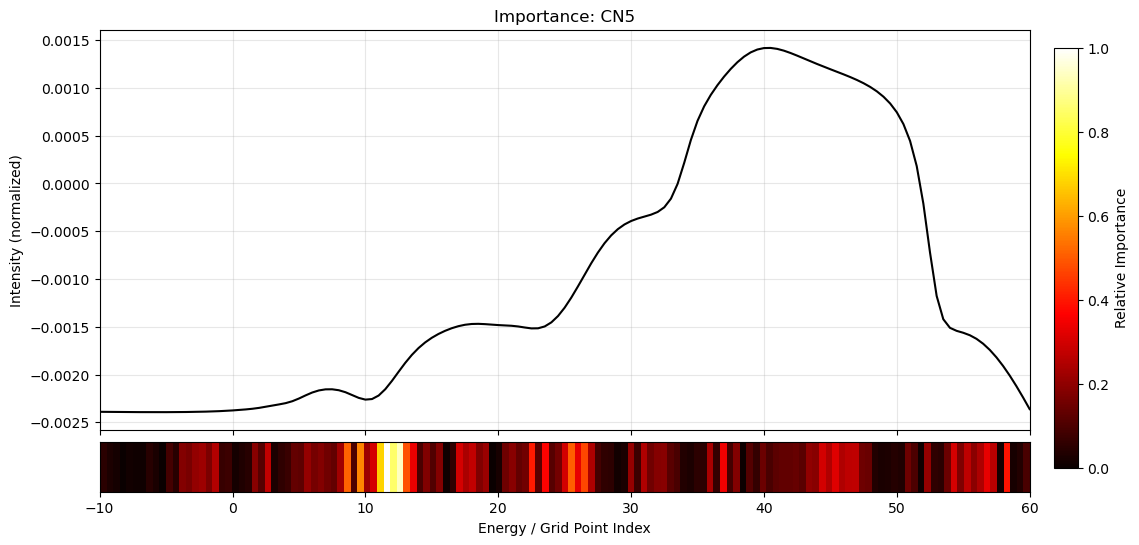

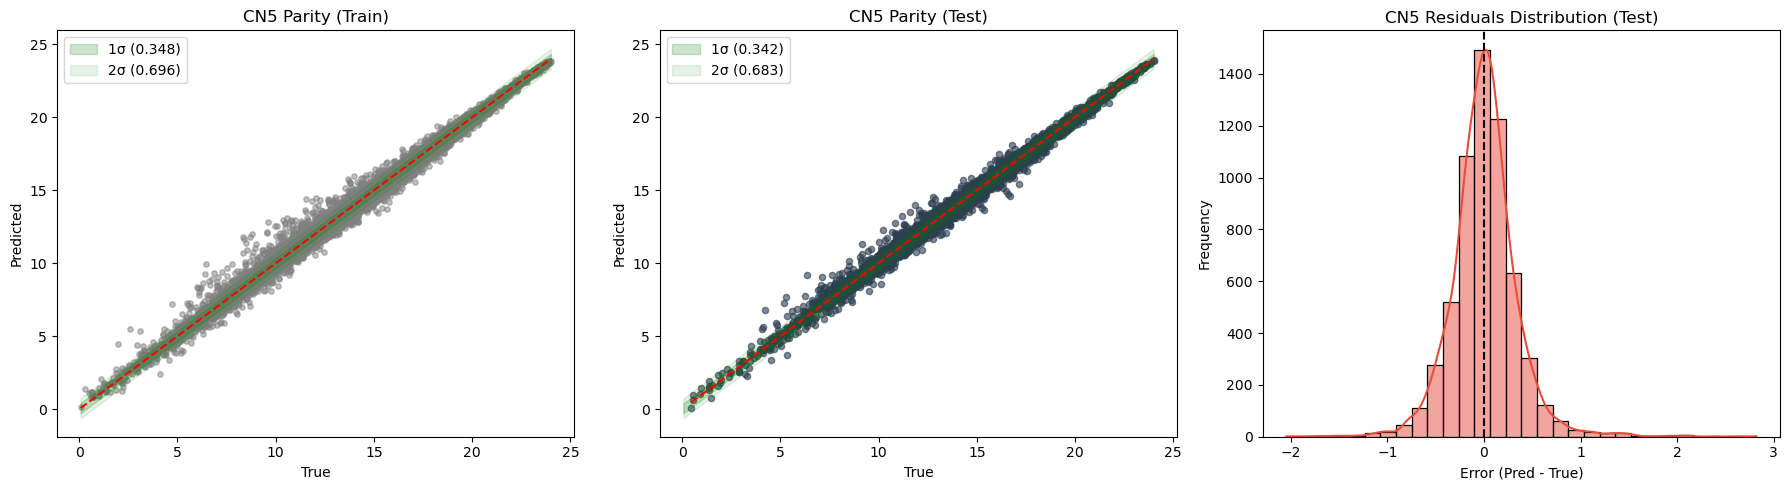


🚀 Моделирование CN6...


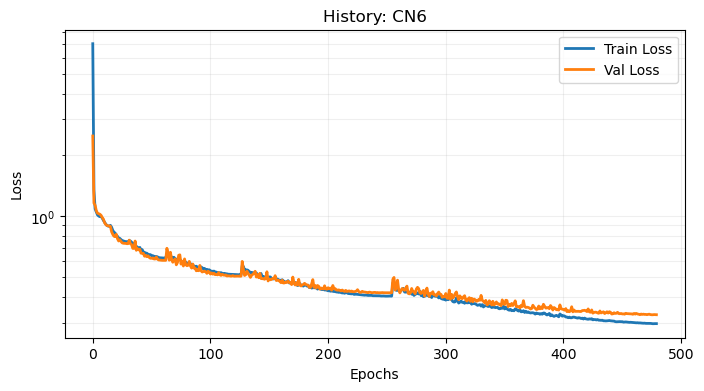

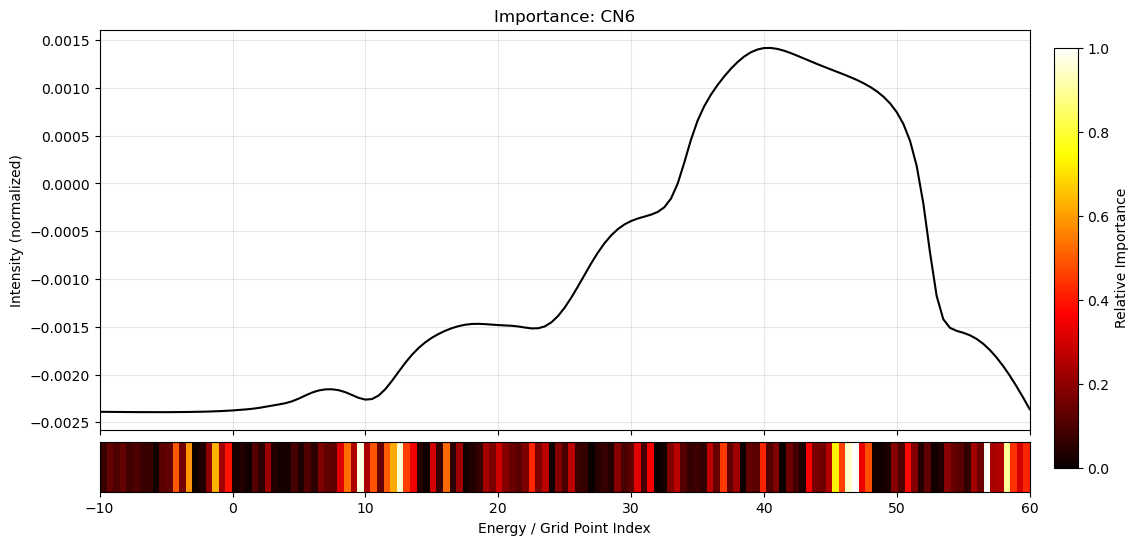

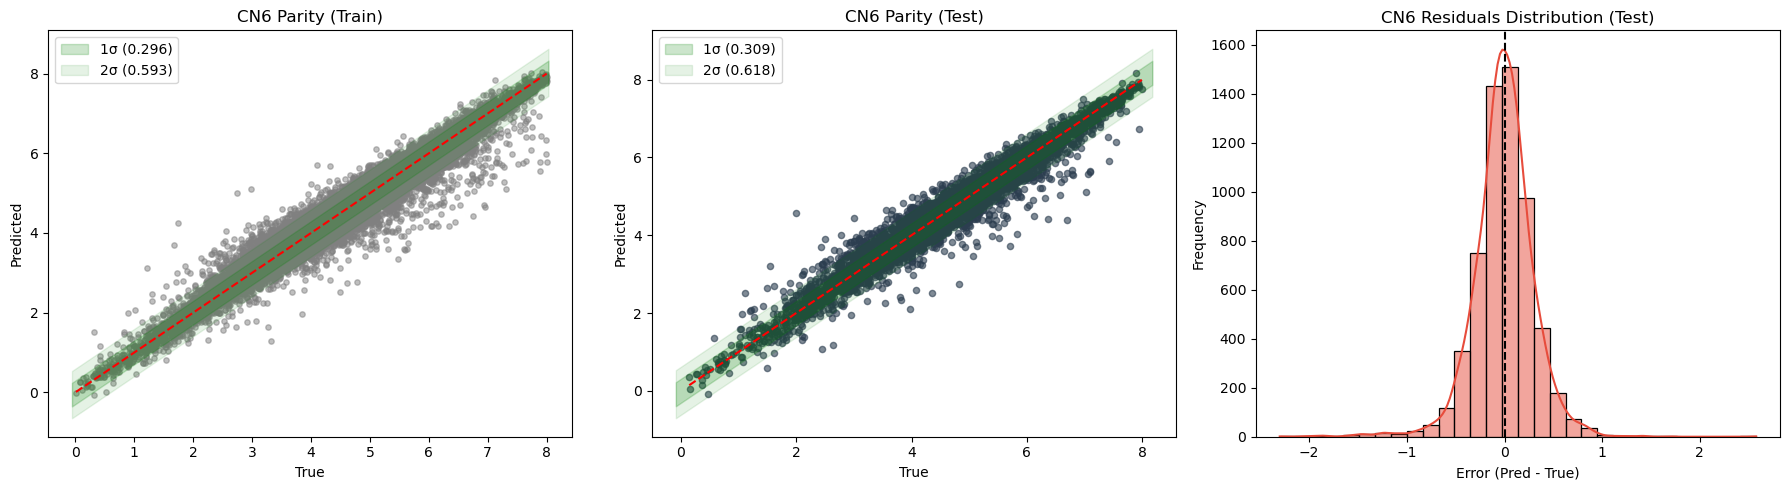


🚀 Моделирование CN7...


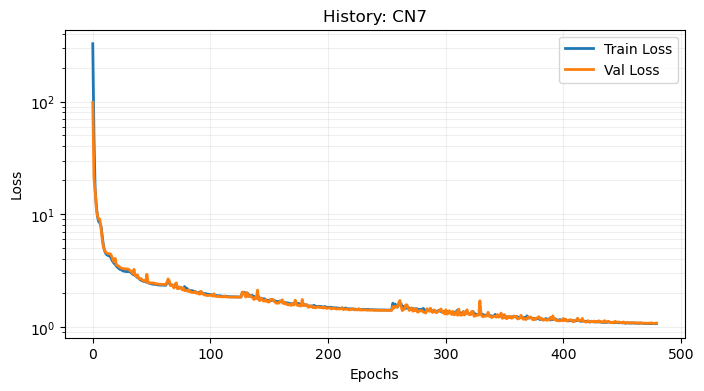

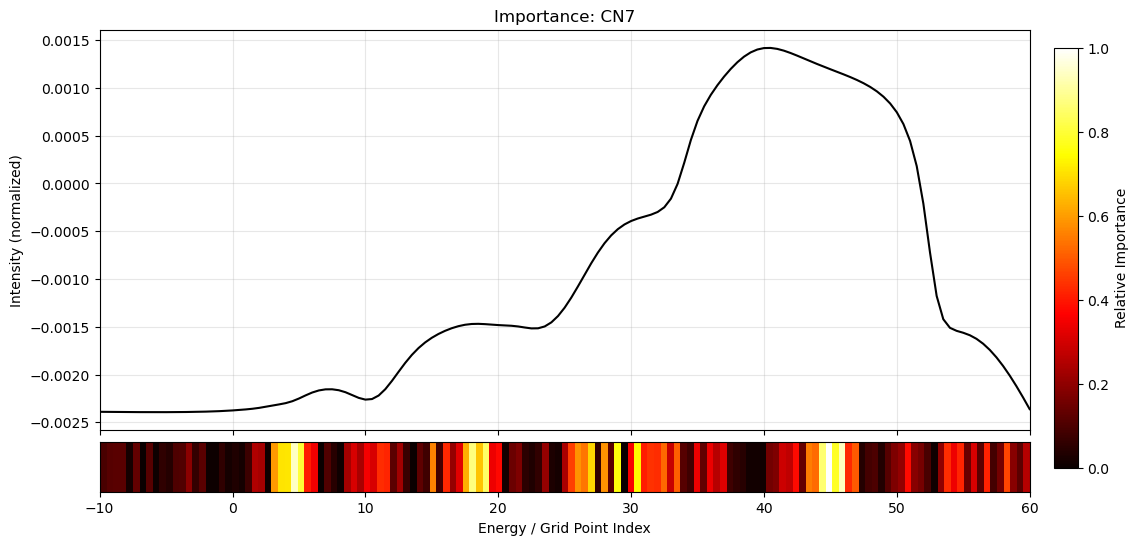

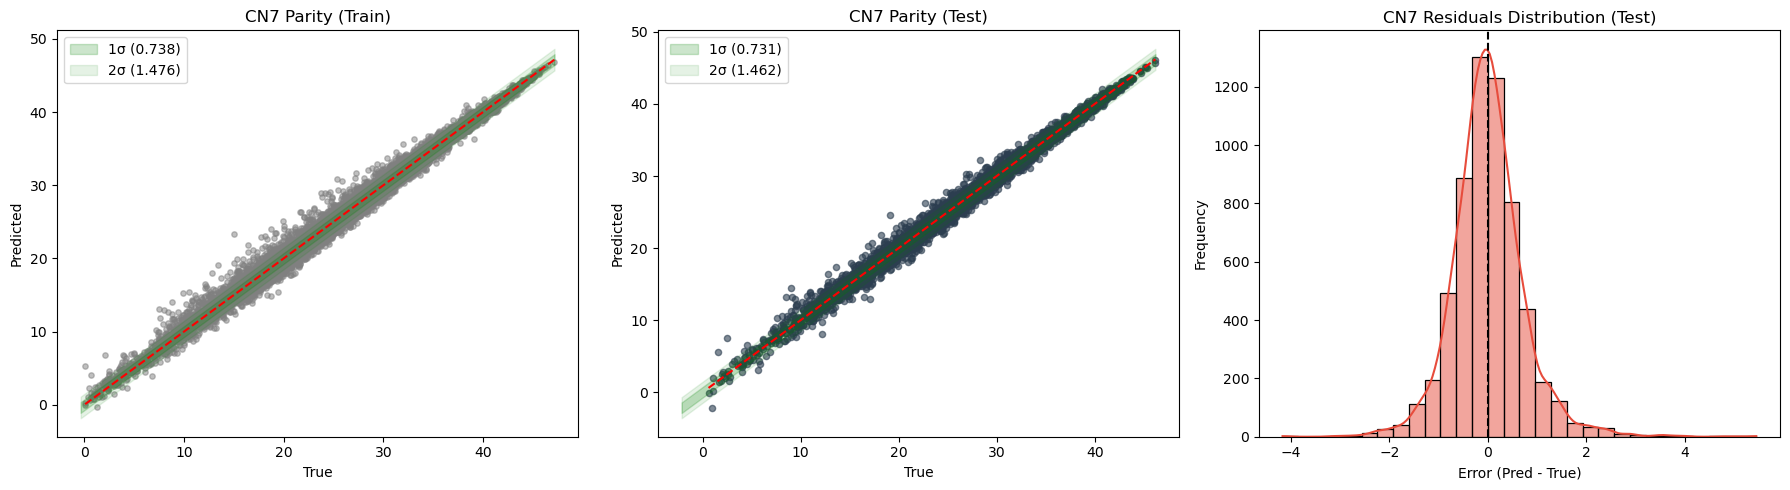


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9996 0.9996 0.9996 0.0281 0.0280 0.0286
CN2    0.9945 0.9941 0.9937 0.0530 0.0530 0.0557
CN3    0.9970 0.9969 0.9962 0.1533 0.1500 0.1605
CN4    0.9977 0.9976 0.9975 0.0707 0.0704 0.0725
CN5    0.9925 0.9921 0.9918 0.2418 0.2415 0.2475
CN6    0.9476 0.9518 0.9439 0.2217 0.2072 0.2260
CN7    0.9910 0.9908 0.9907 0.5271 0.5252 0.5319
CPU times: total: 35min 59s
Wall time: 35min 30s


In [6]:
%%time
save_root = Path('../processed_data/Results/JanisLike/CNN/')  
model = XANES_CNN(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_JanisLike, save_root=save_root)

### Cценарий1B (NotJanisLike)


🚀 Моделирование CN1...


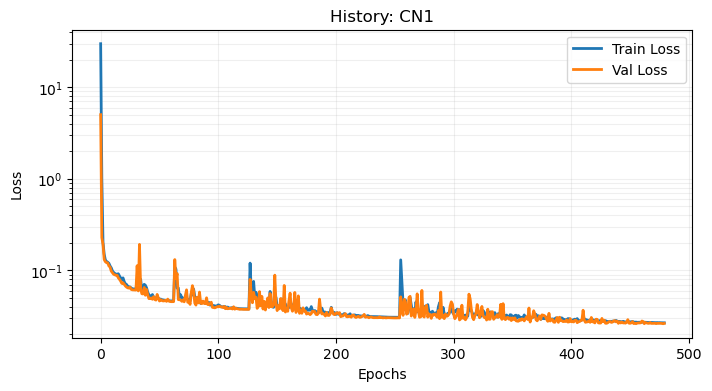

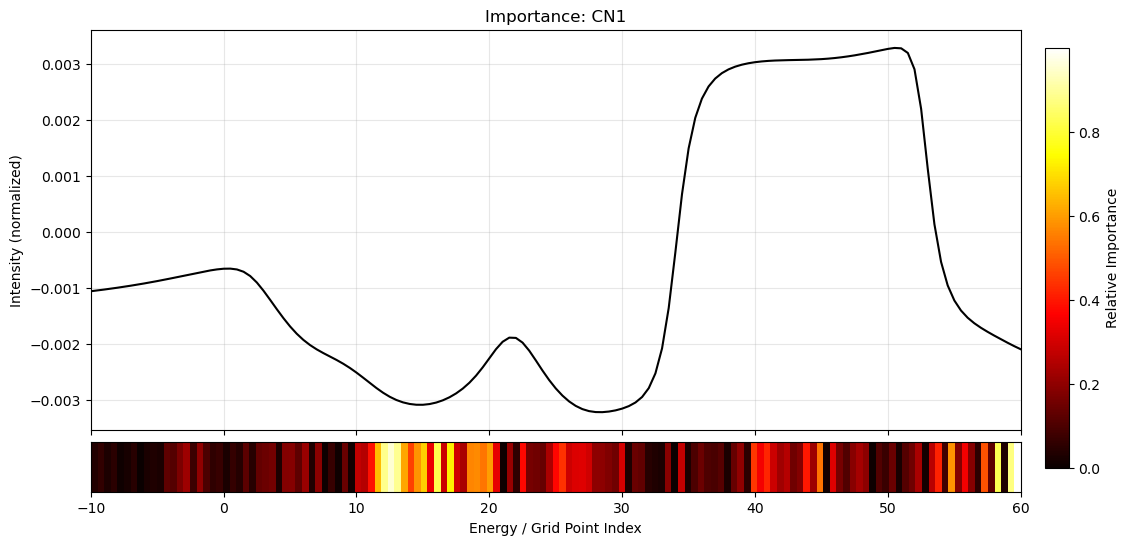

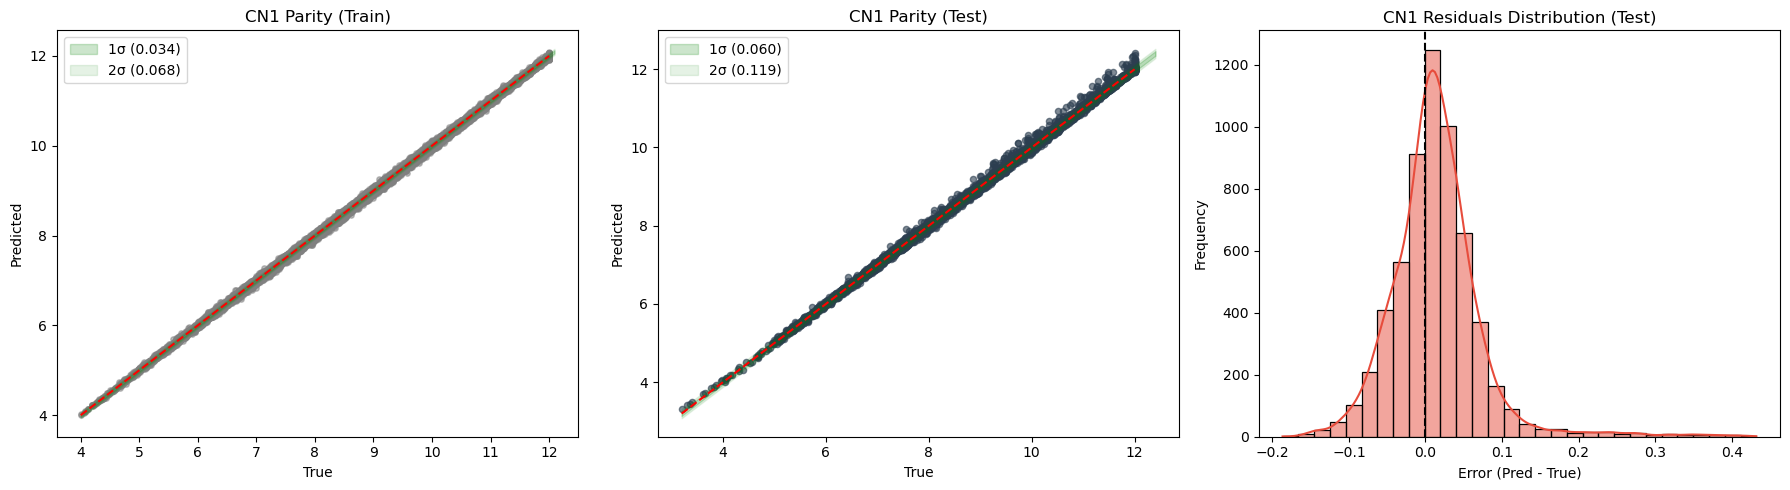


🚀 Моделирование CN2...


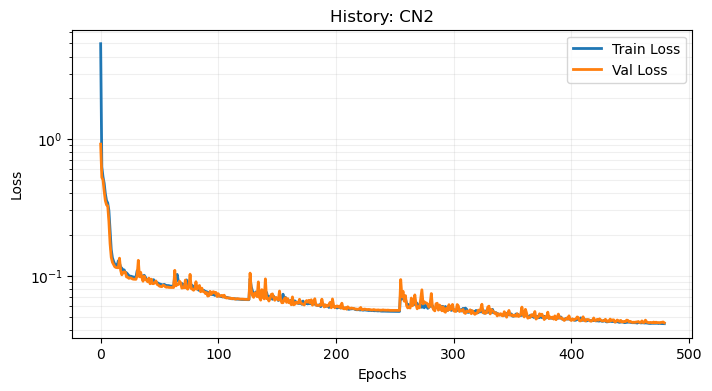

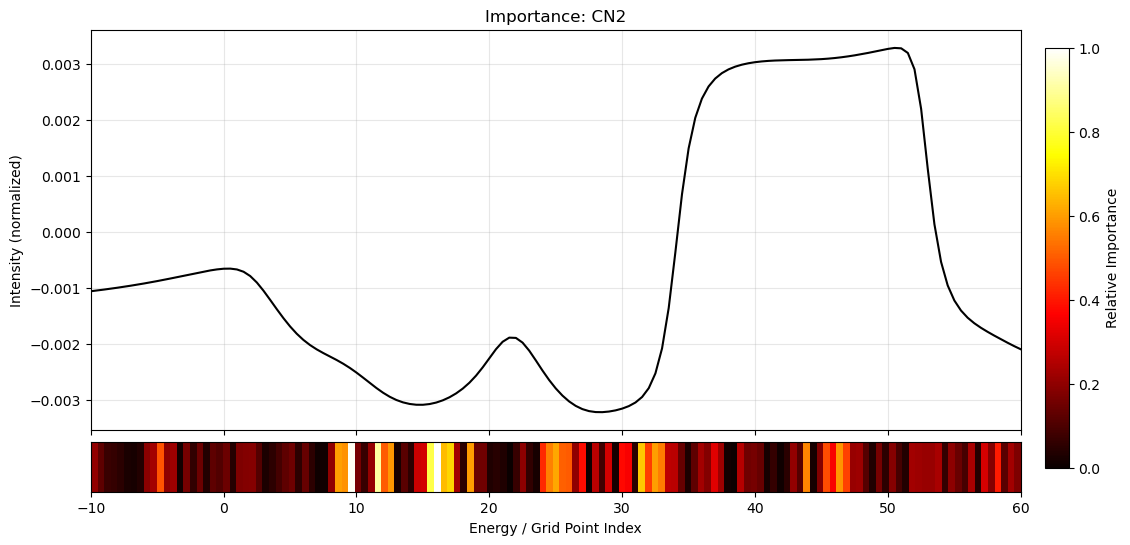

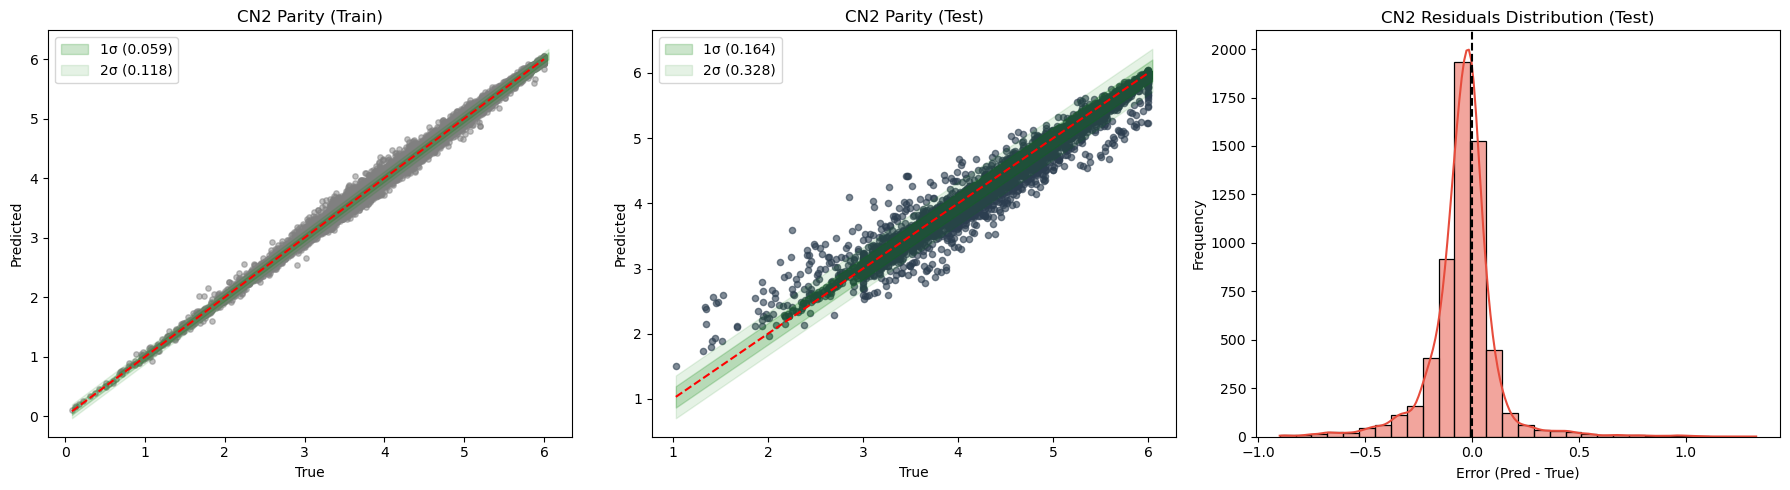


🚀 Моделирование CN3...


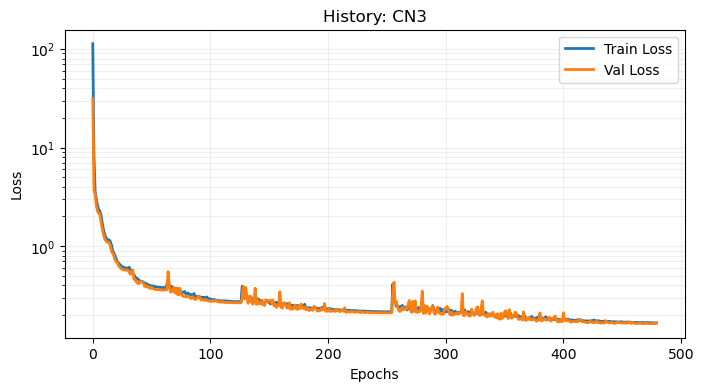

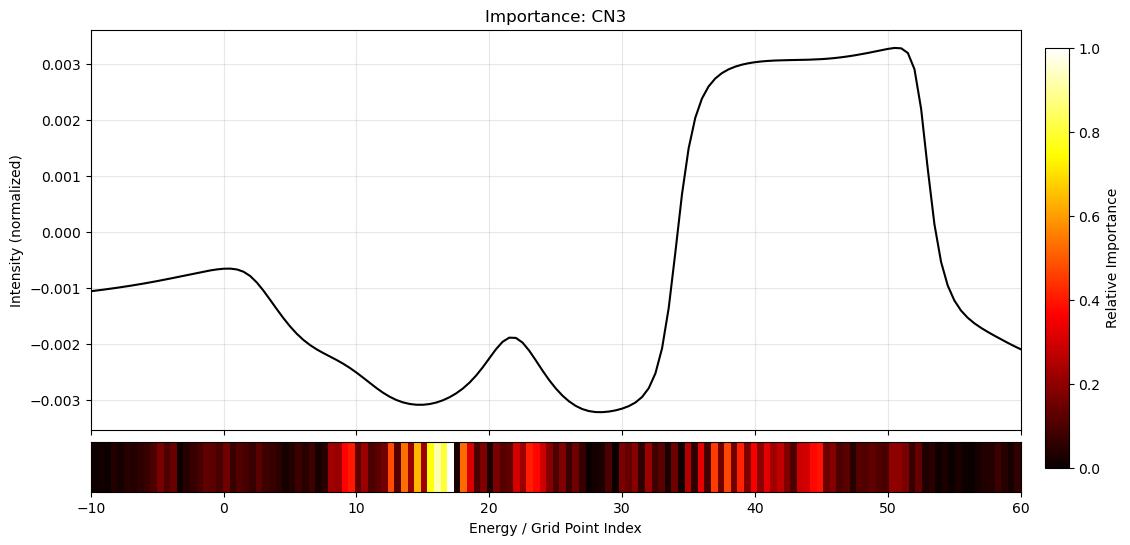

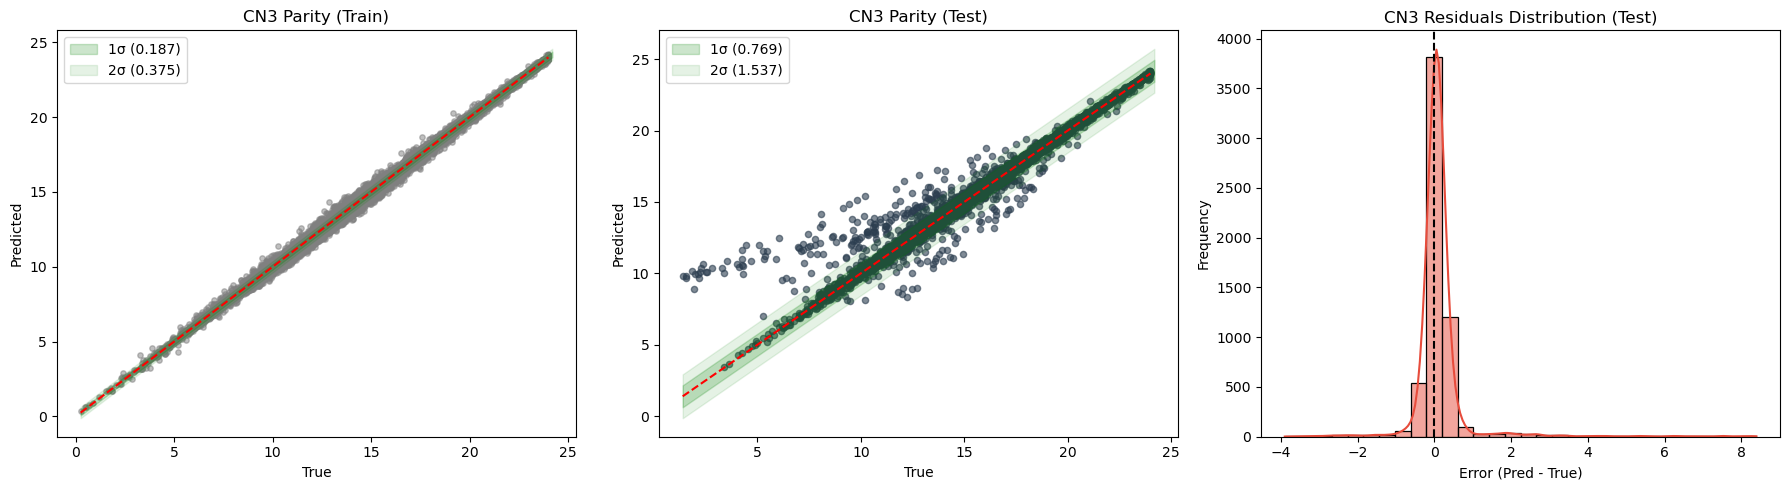


🚀 Моделирование CN4...


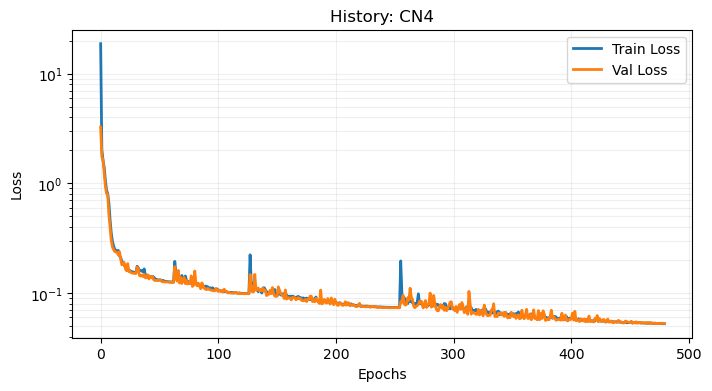

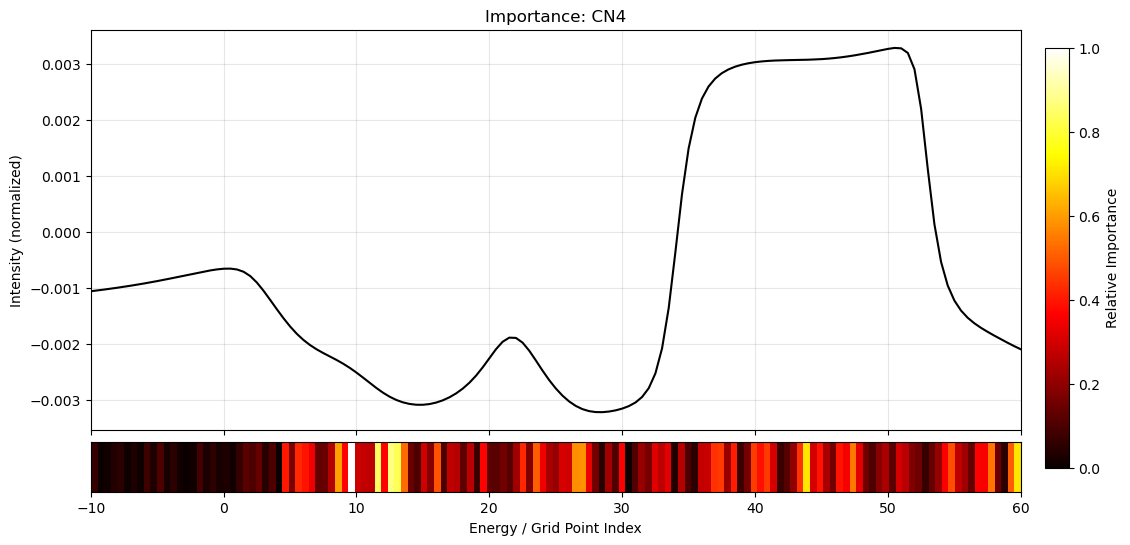

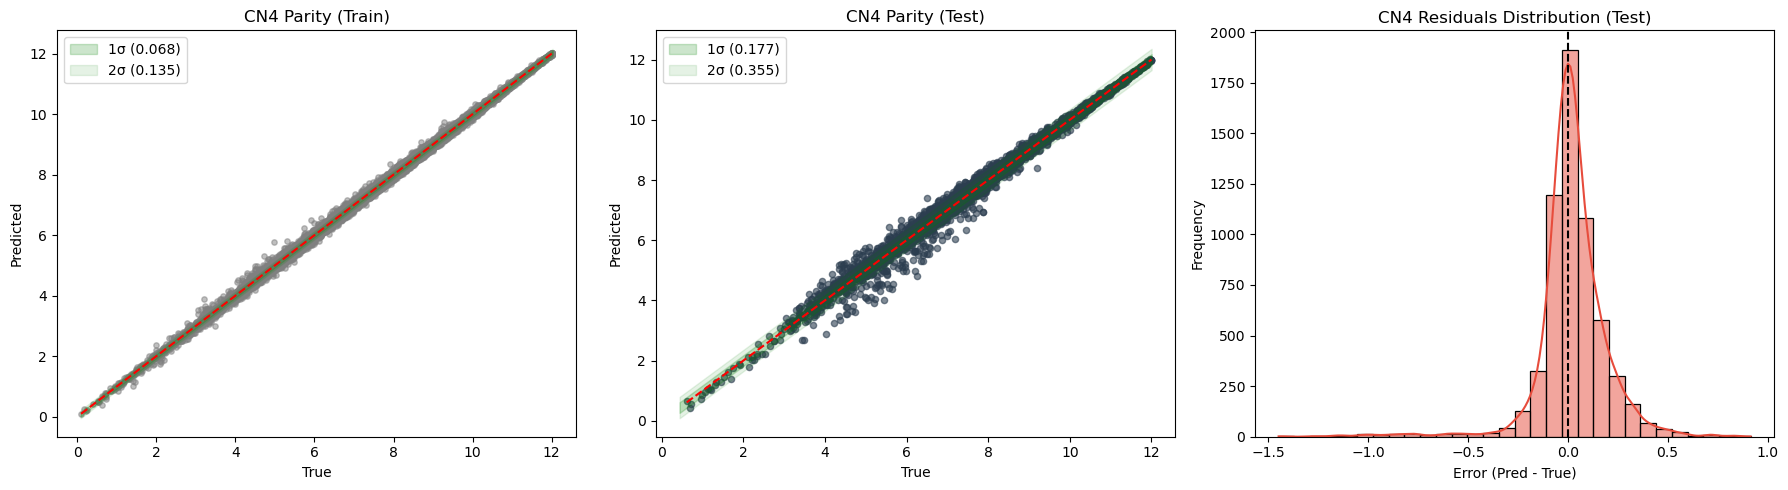


🚀 Моделирование CN5...


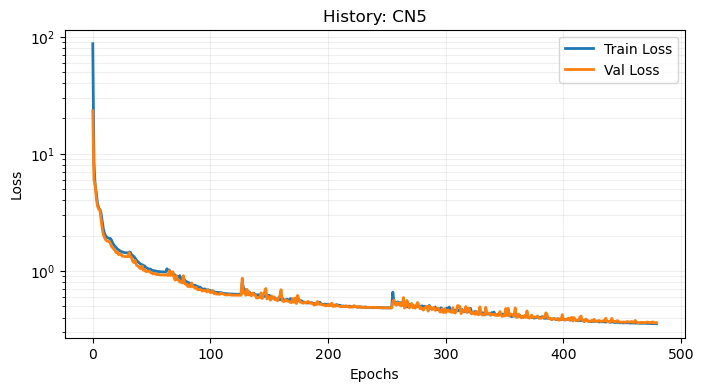

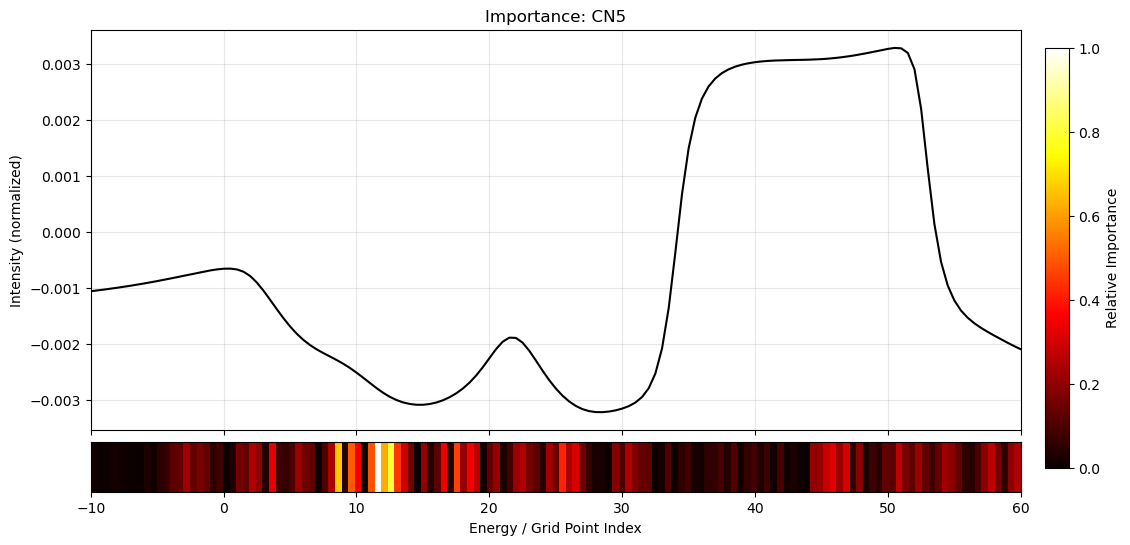

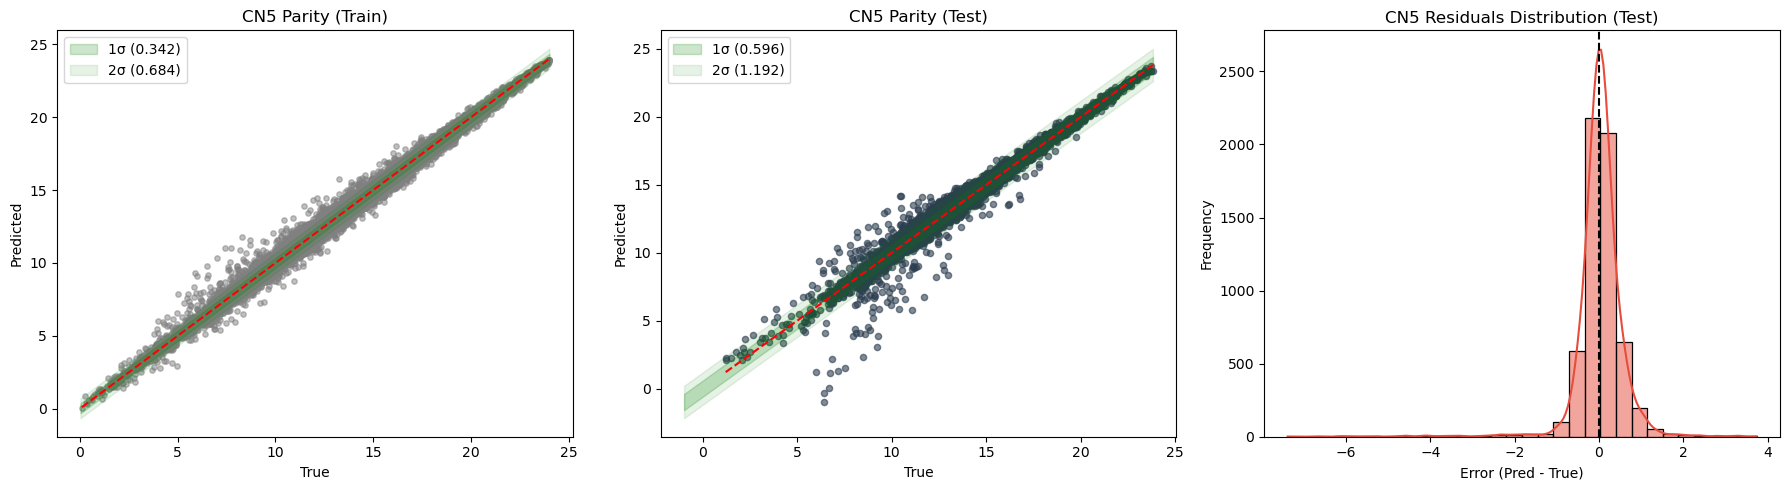


🚀 Моделирование CN6...


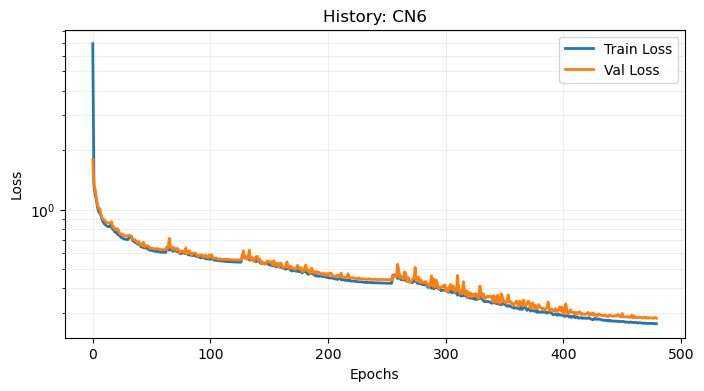

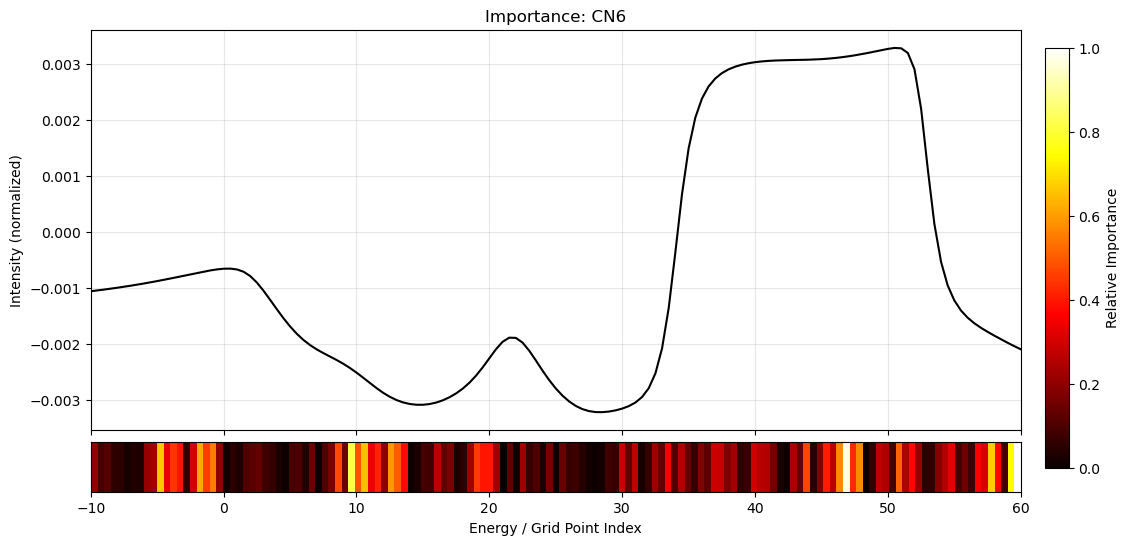

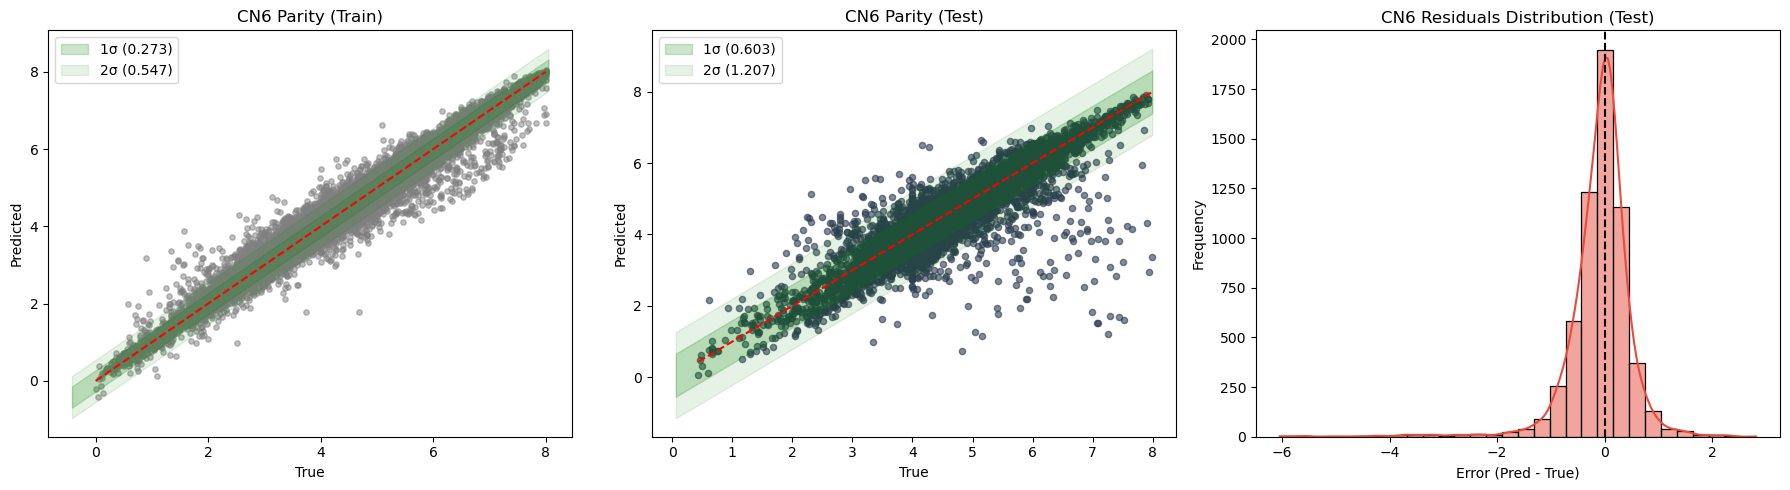


🚀 Моделирование CN7...


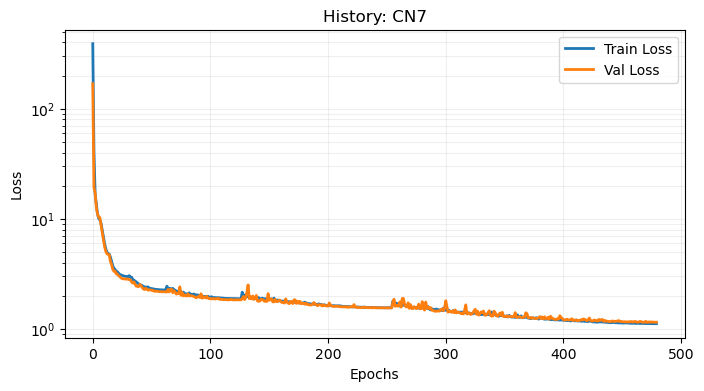

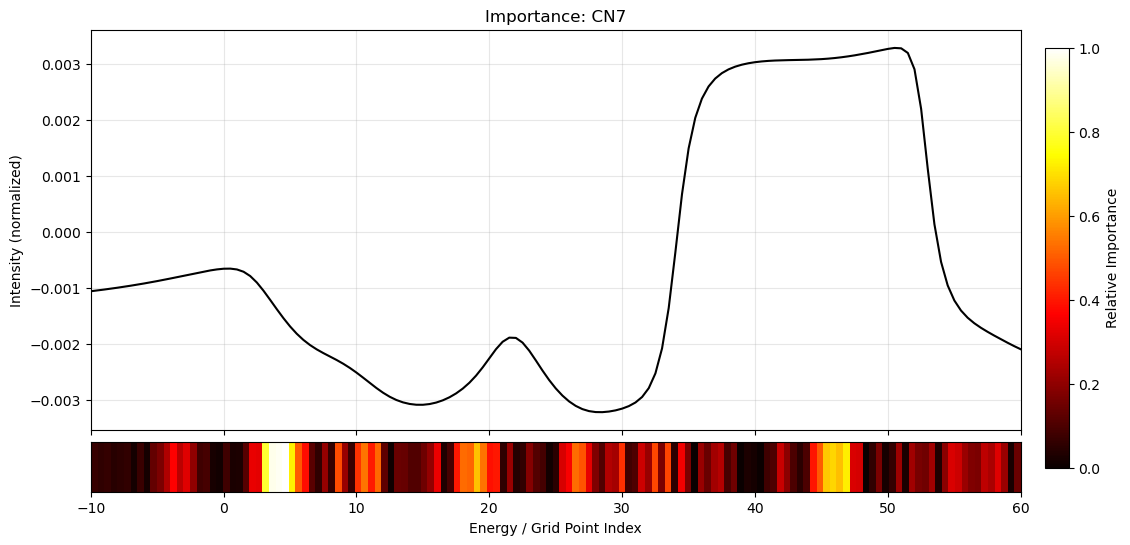

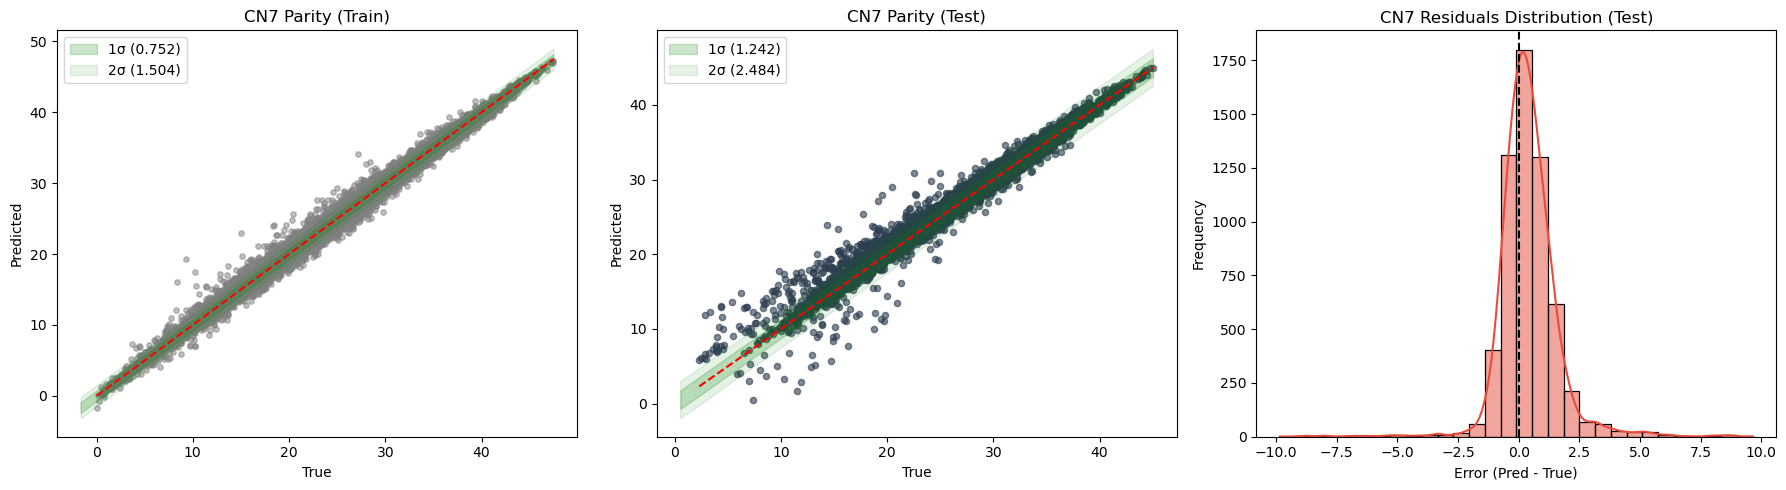


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9990 0.9997 0.9997 0.0415 0.0254 0.0250
CN2    0.9673 0.9971 0.9970 0.1048 0.0409 0.0416
CN3    0.9614 0.9982 0.9983 0.3063 0.1310 0.1292
CN4    0.9912 0.9990 0.9991 0.1117 0.0480 0.0482
CN5    0.9722 0.9933 0.9932 0.3410 0.2368 0.2399
CN6    0.7434 0.9657 0.9631 0.3772 0.1883 0.1995
CN7    0.9654 0.9916 0.9913 0.8492 0.5484 0.5602
CPU times: total: 38min 38s
Wall time: 38min 16s


In [7]:
%%time
save_root = Path('../processed_data/Results/NotJanisLike/CNN/')  
model = XANES_CNN(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_NotJanisLike, save_root=save_root)

###  Сценарий 2А No_Strict (Возможна утечка данных)


🚀 Моделирование CN1...


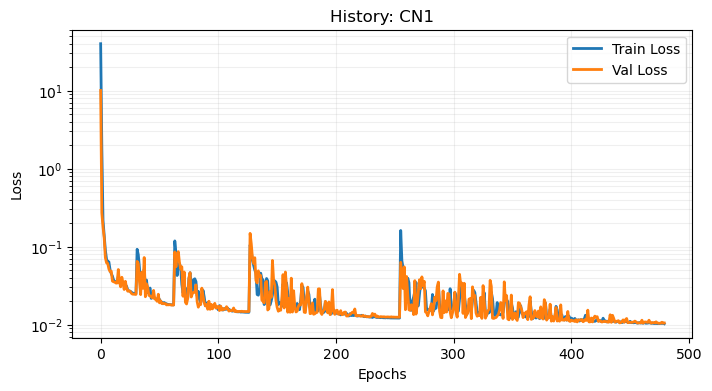

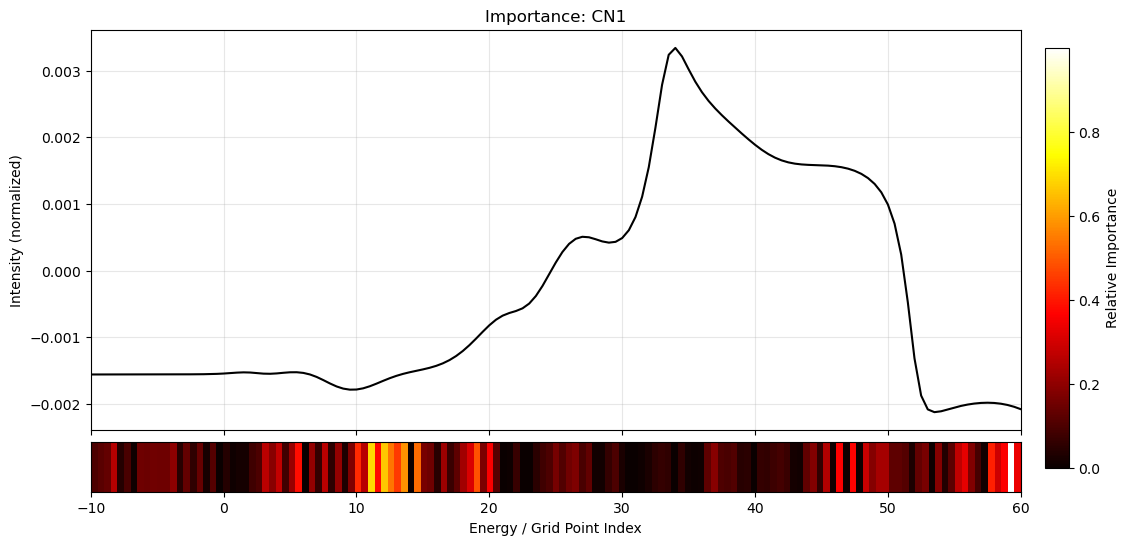

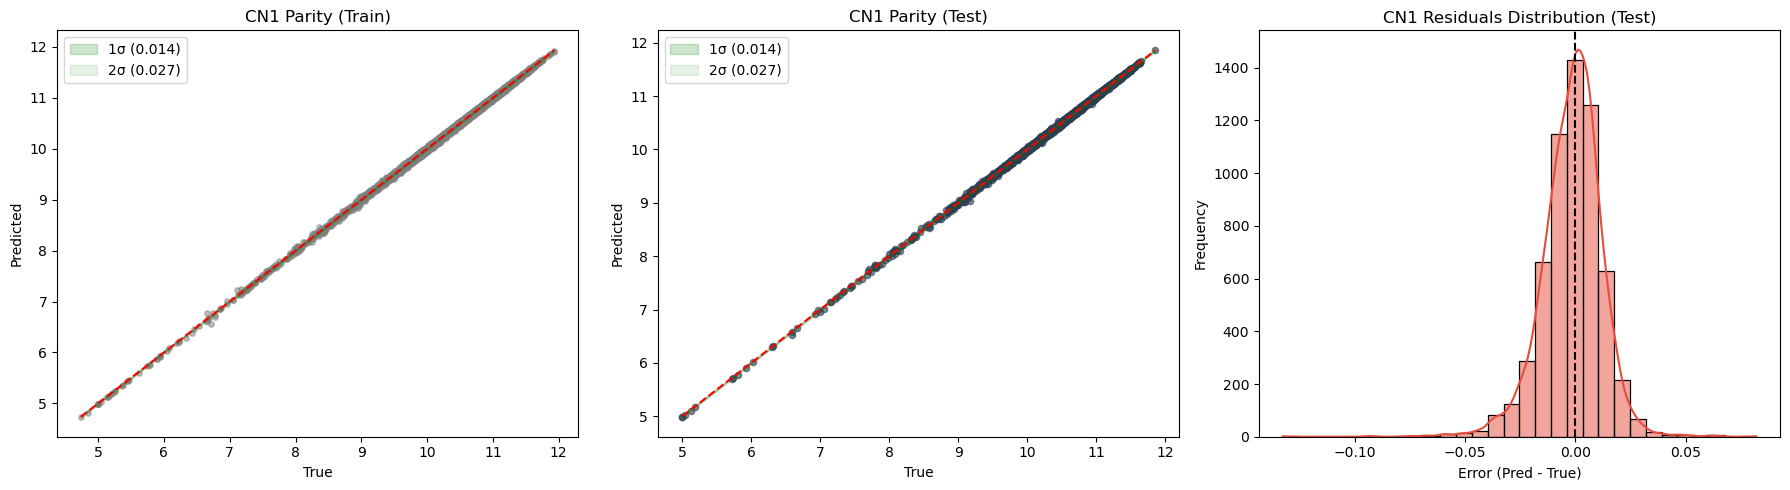


🚀 Моделирование CN2...


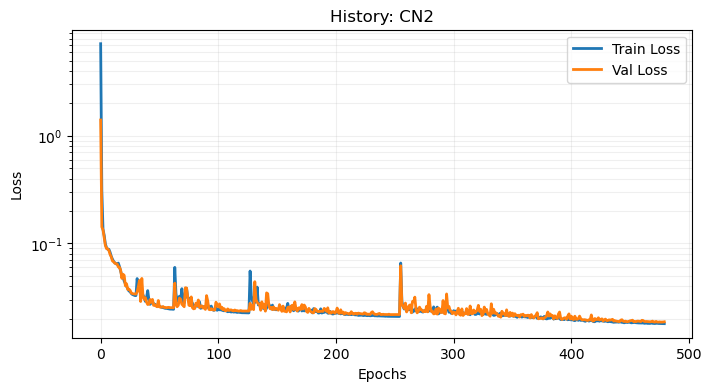

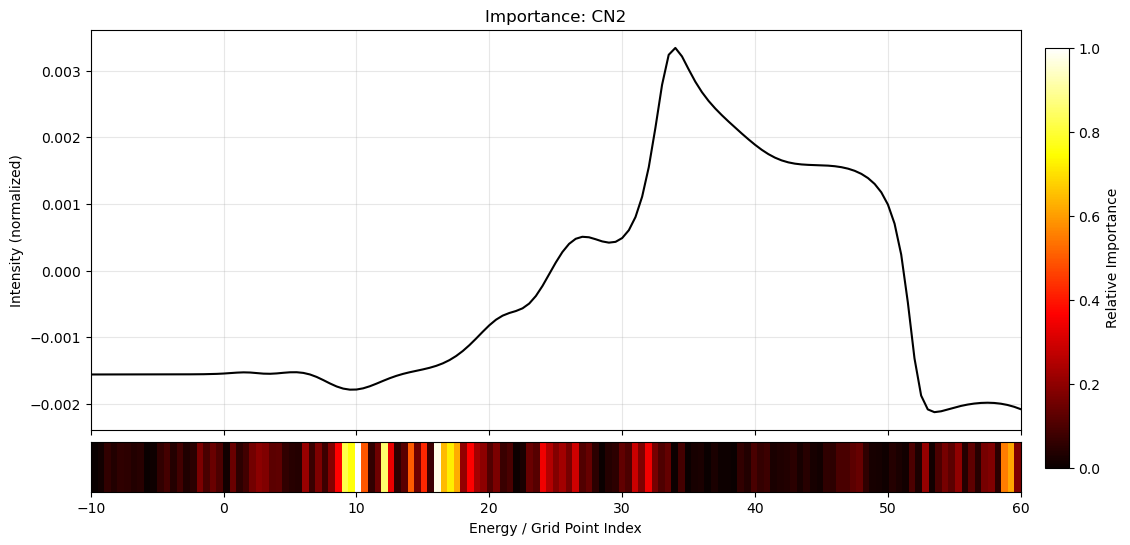

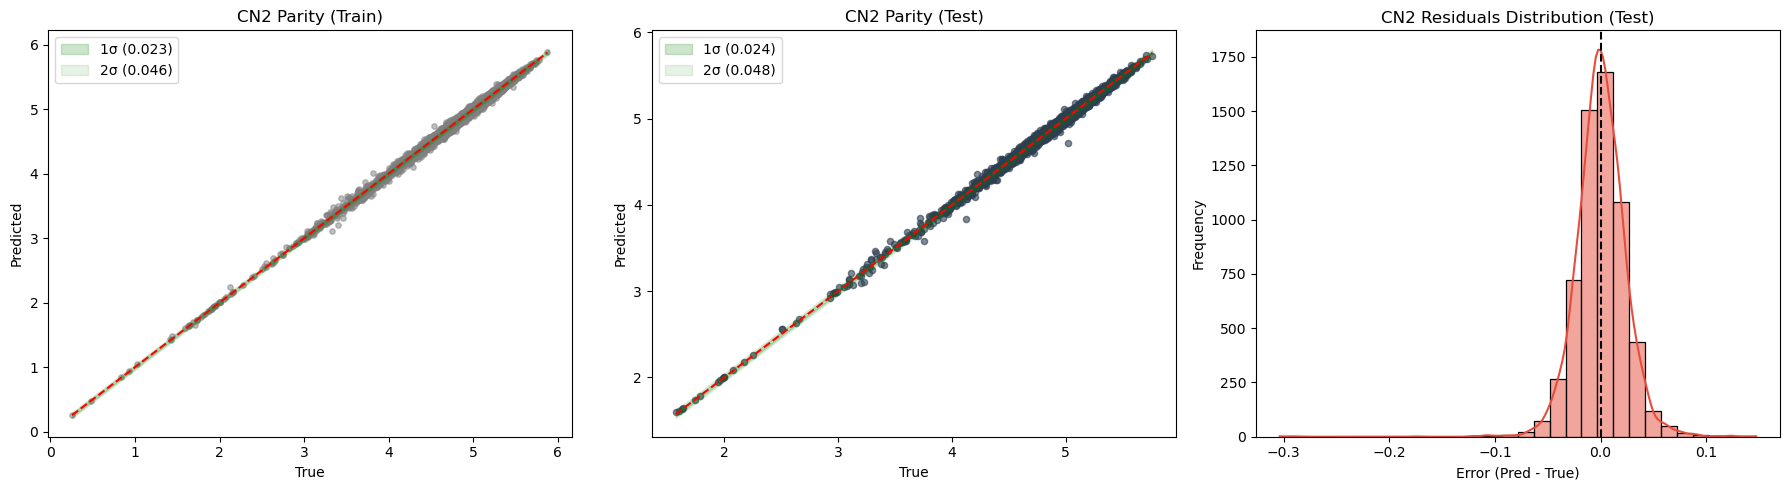


🚀 Моделирование CN3...


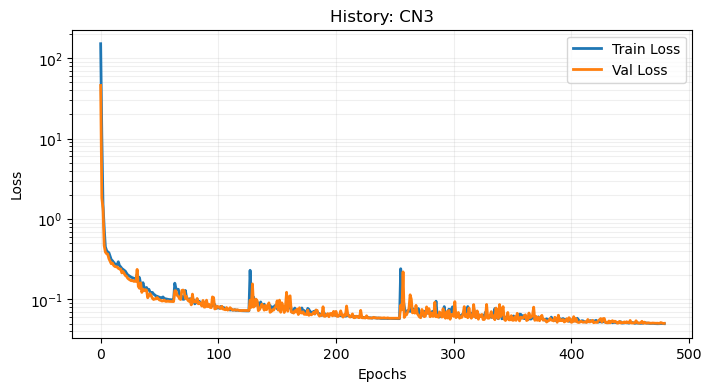

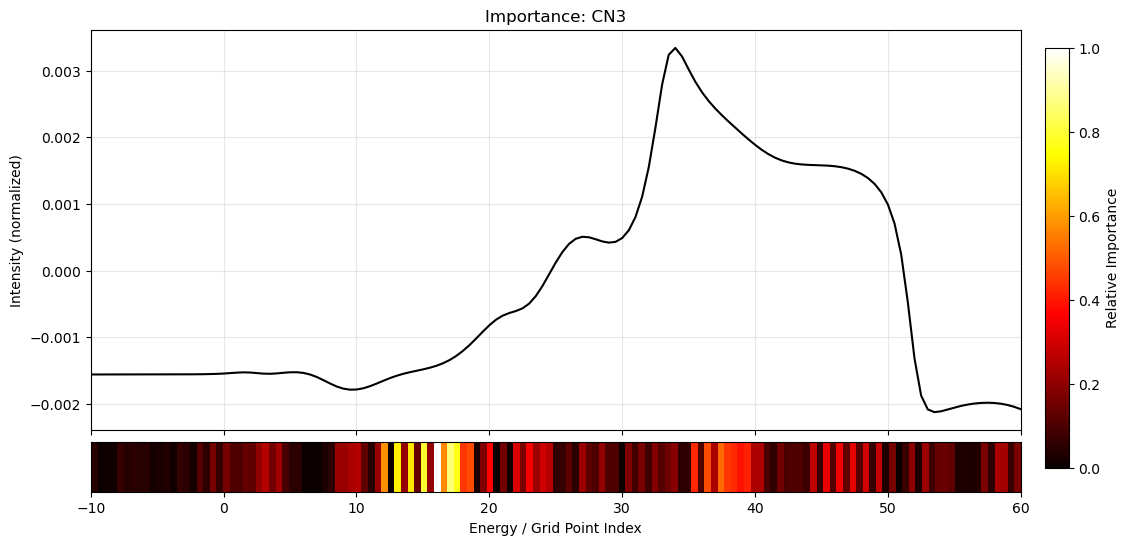

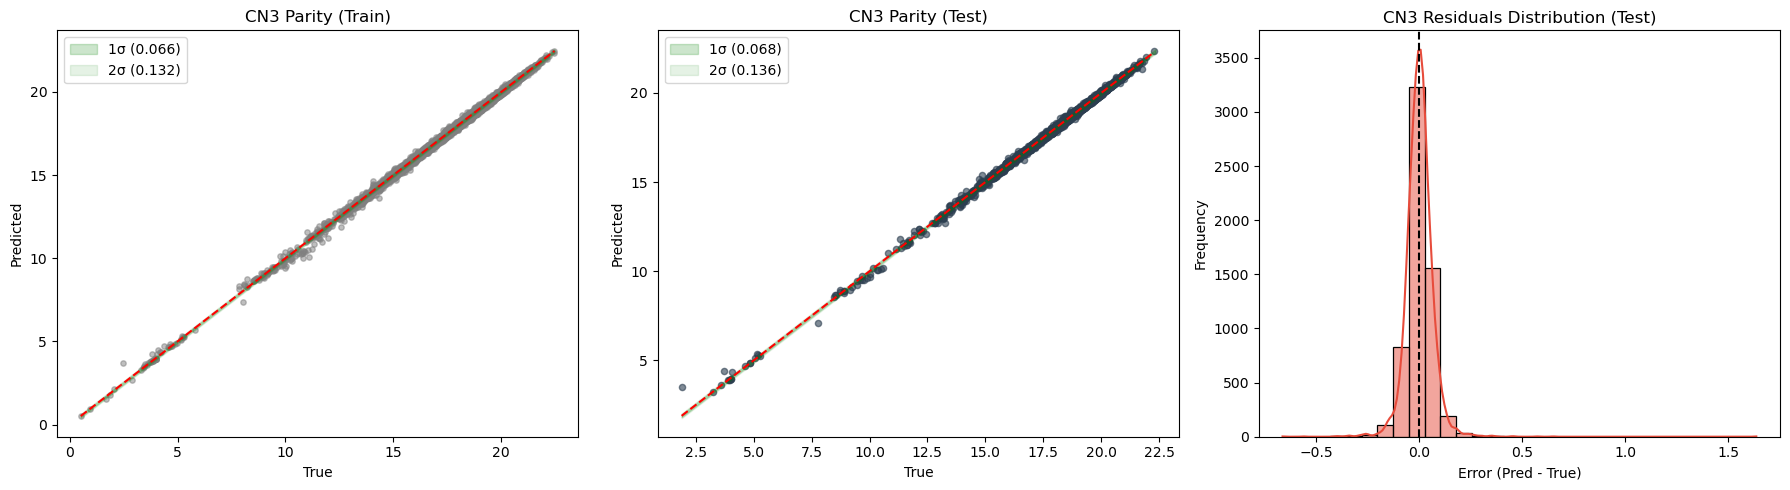


🚀 Моделирование CN4...


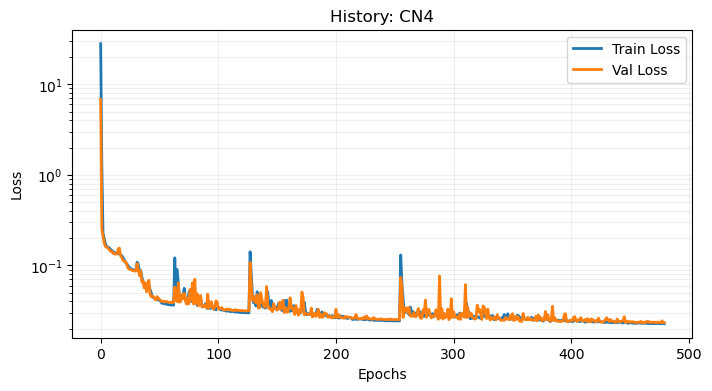

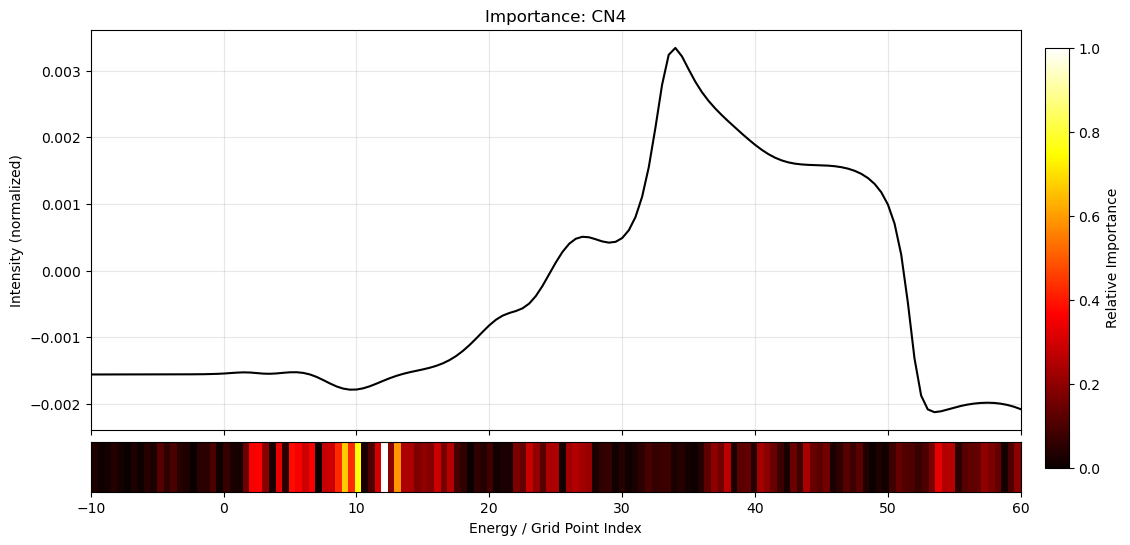

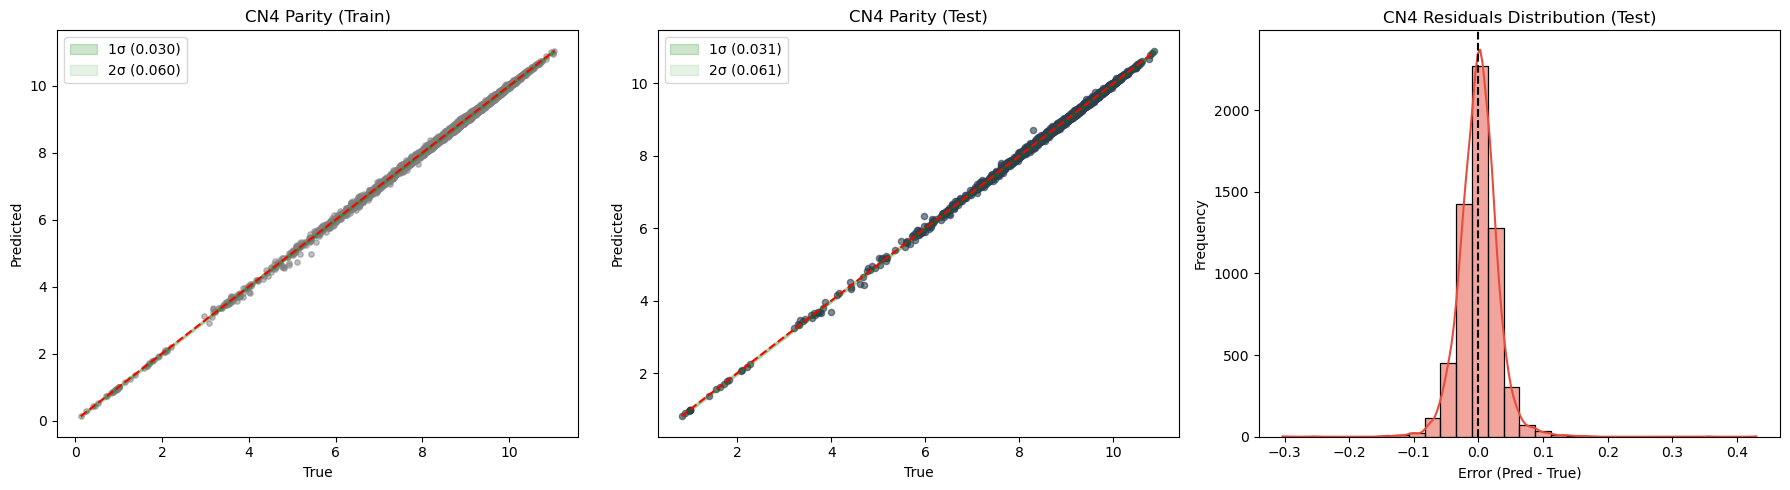


🚀 Моделирование CN5...


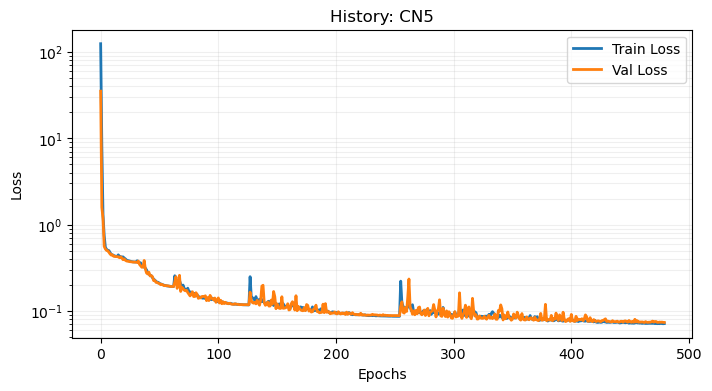

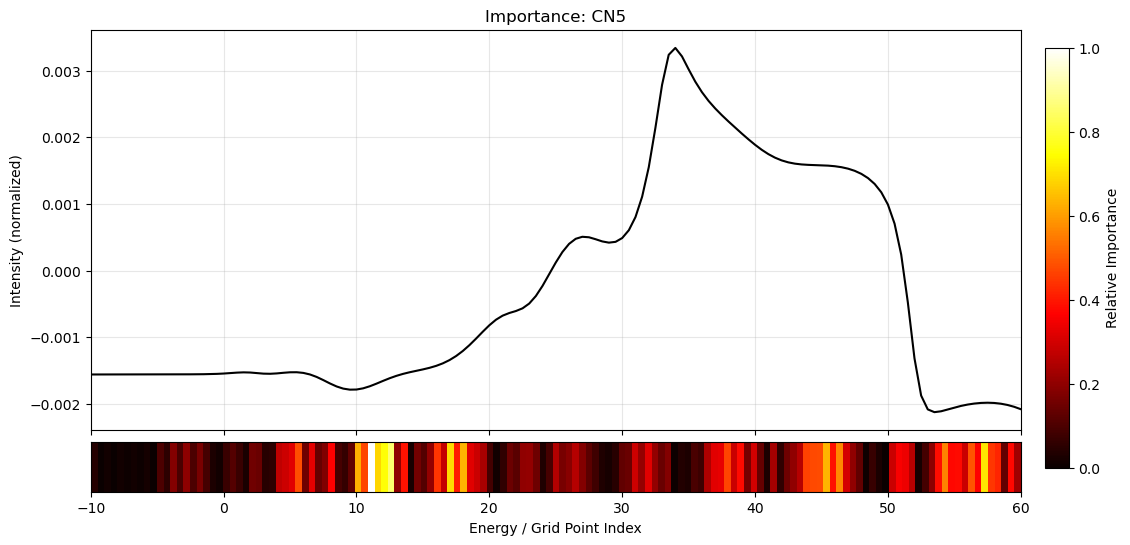

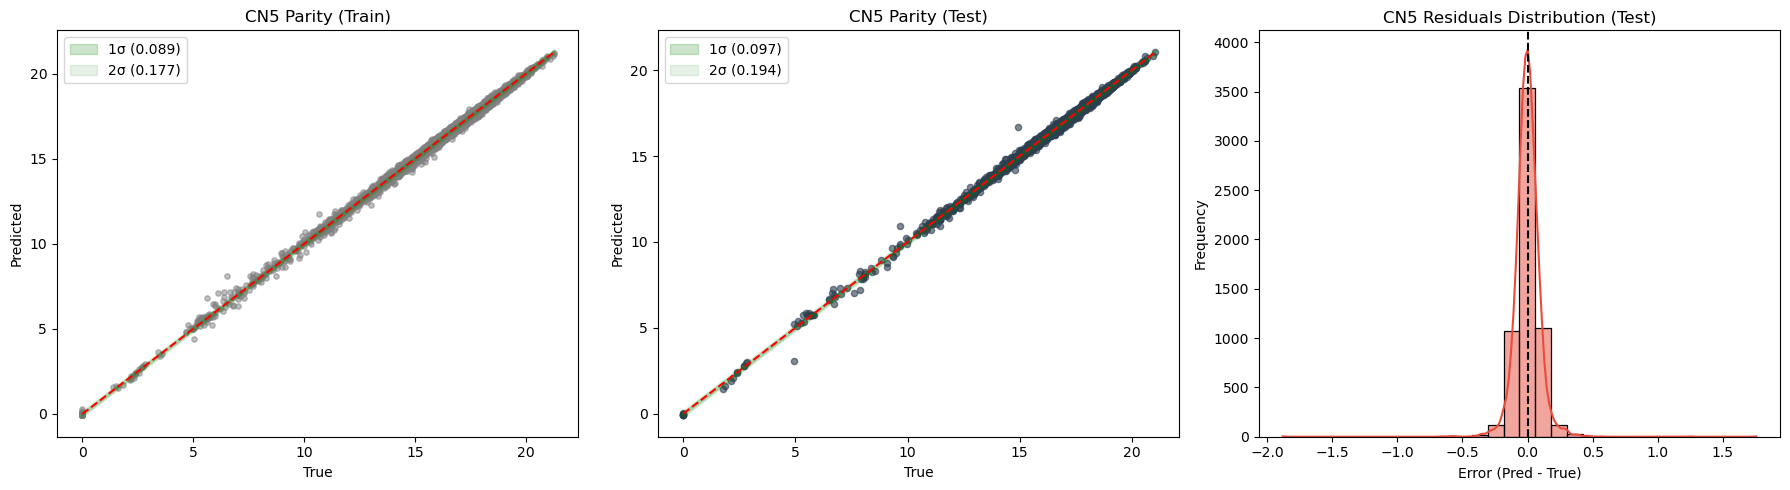


🚀 Моделирование CN6...


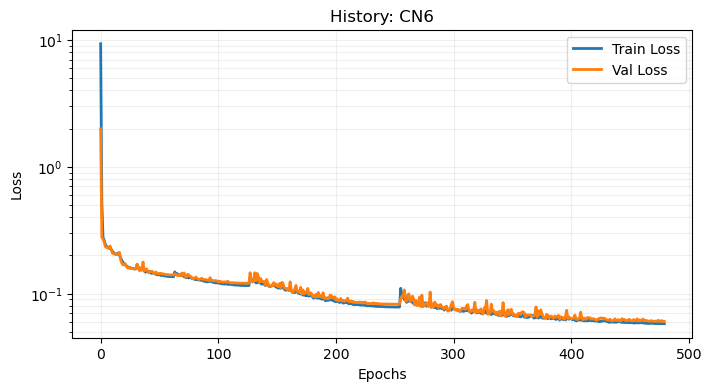

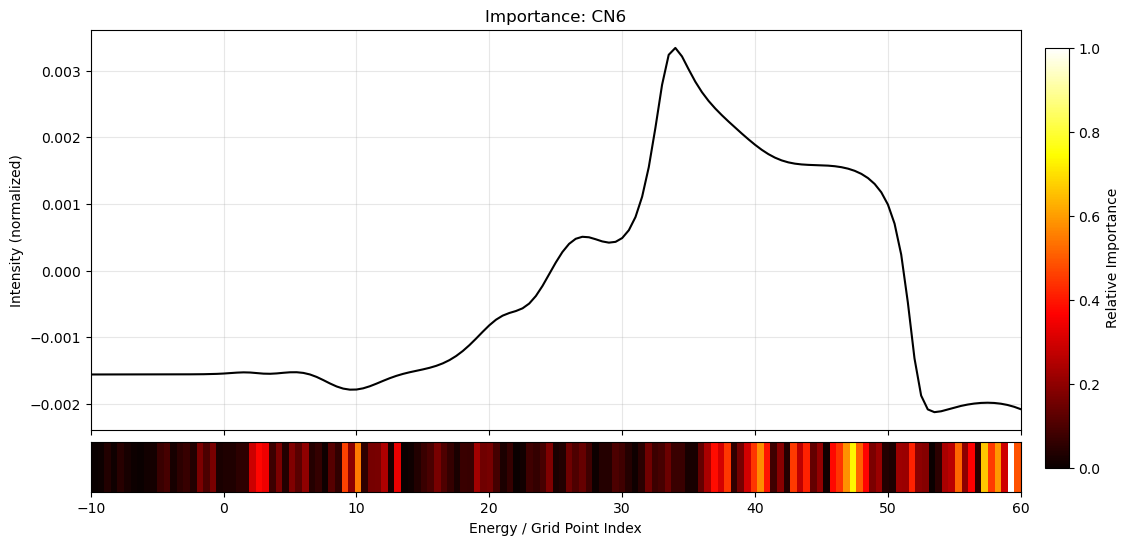

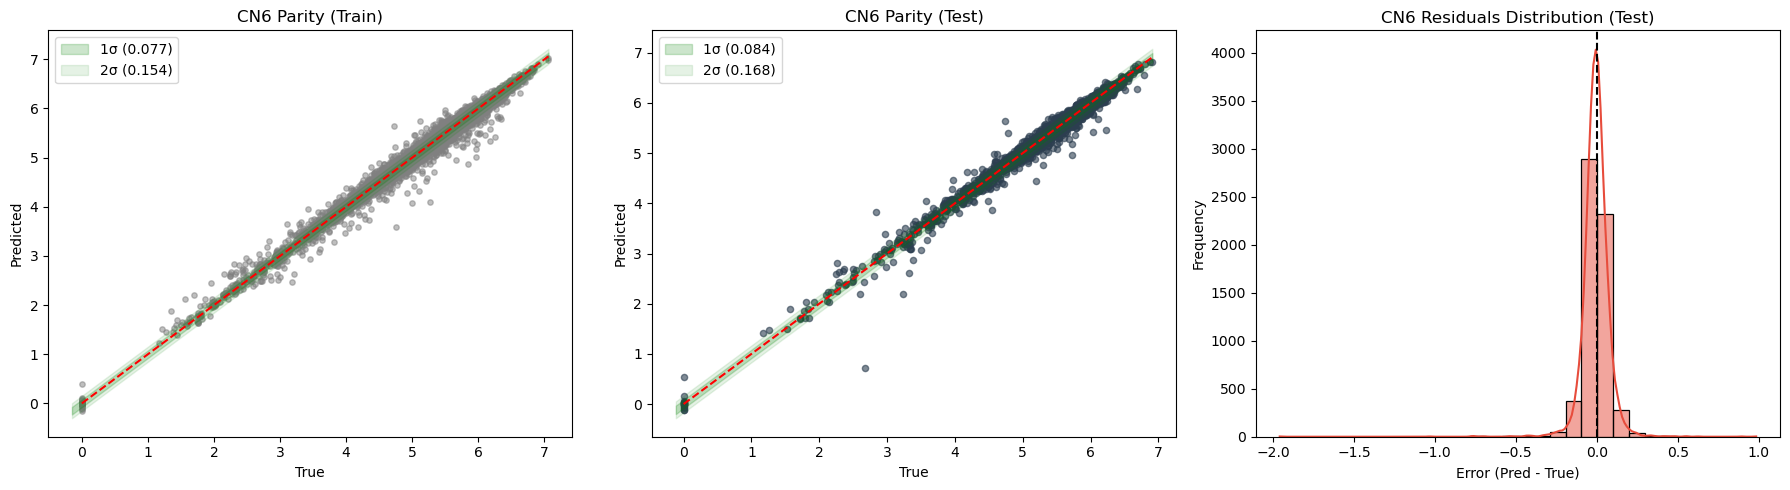


🚀 Моделирование CN7...


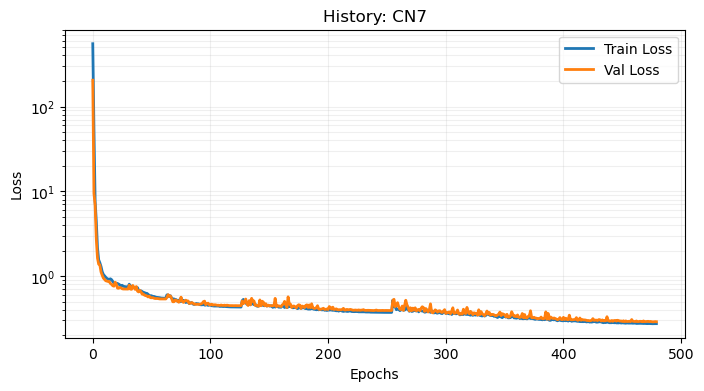

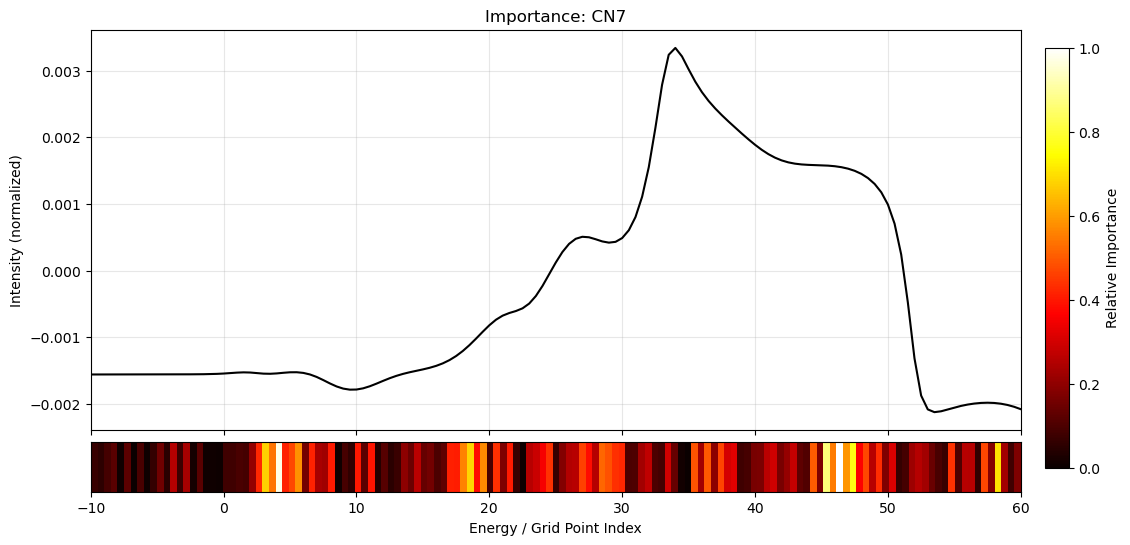

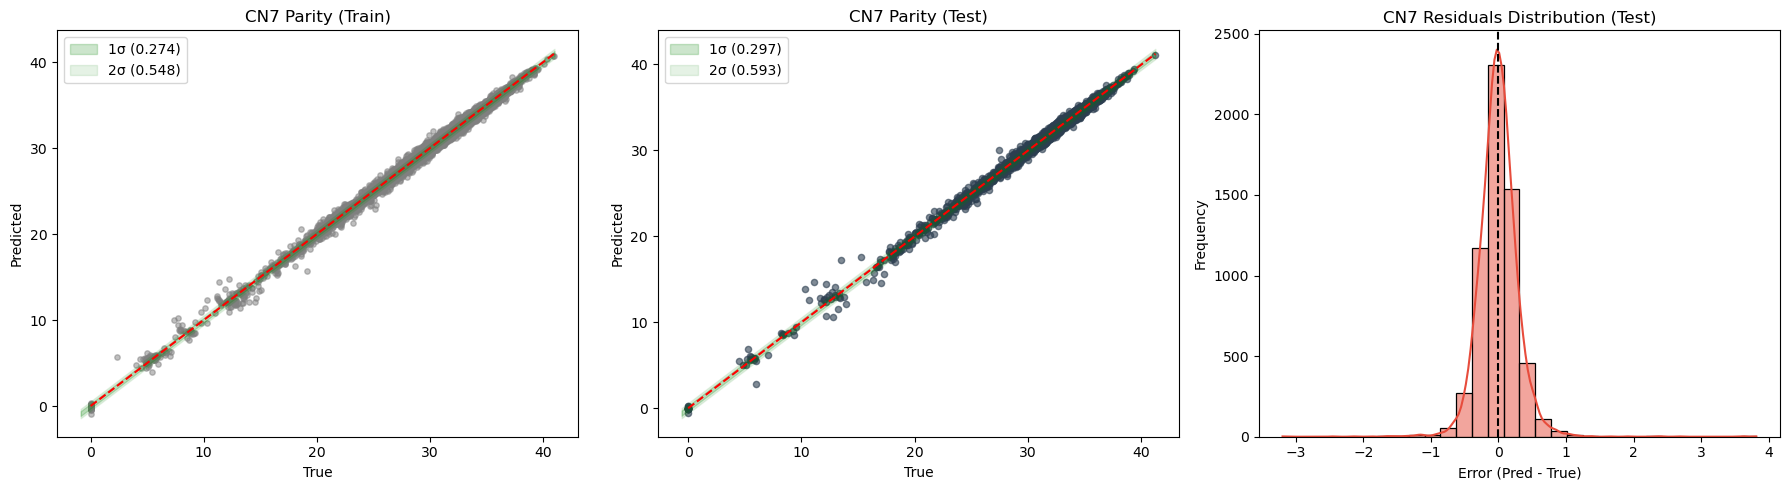


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9994 0.9994 0.9994 0.0101 0.0101 0.0103
CN2    0.9954 0.9958 0.9952 0.0175 0.0173 0.0180
CN3    0.9982 0.9983 0.9981 0.0455 0.0452 0.0461
CN4    0.9987 0.9988 0.9985 0.0220 0.0217 0.0223
CN5    0.9971 0.9976 0.9971 0.0657 0.0630 0.0650
CN6    0.9832 0.9861 0.9831 0.0536 0.0520 0.0537
CN7    0.9942 0.9951 0.9940 0.2066 0.1992 0.2064
CPU times: total: 39min 43s
Wall time: 39min 23s


In [8]:
%%time
save_root = Path('../processed_data/Results/No_Strict_2A/CNN/')  
model = XANES_CNN(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_No_Strict, save_root=save_root)

### Сценарий 2B Lauvian


🚀 Моделирование CN1...


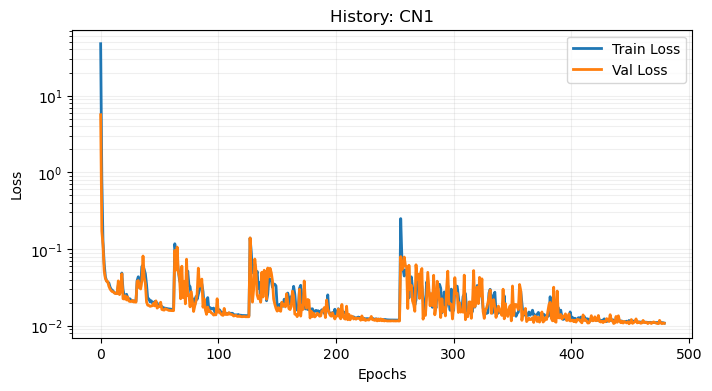

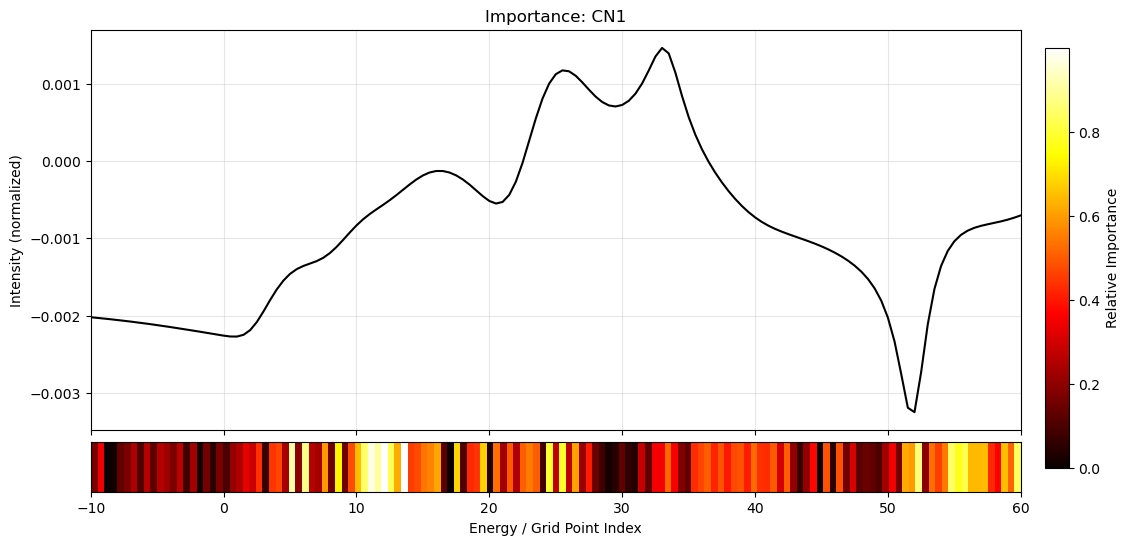

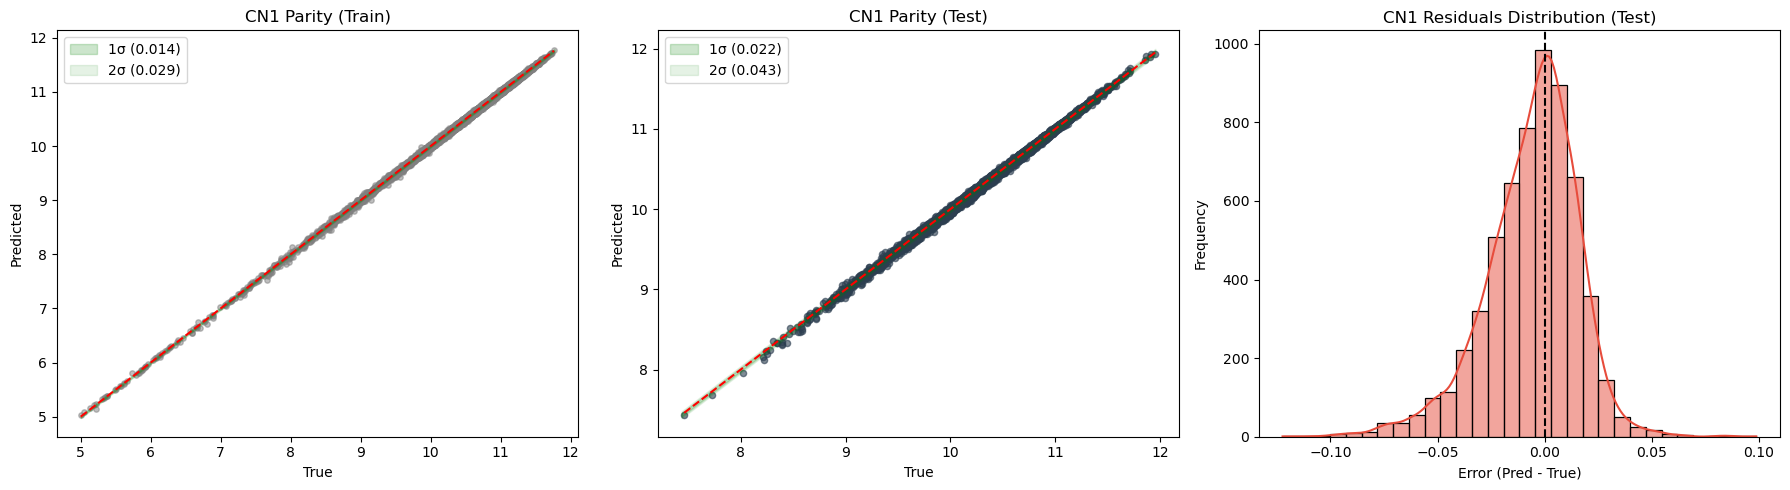


🚀 Моделирование CN2...


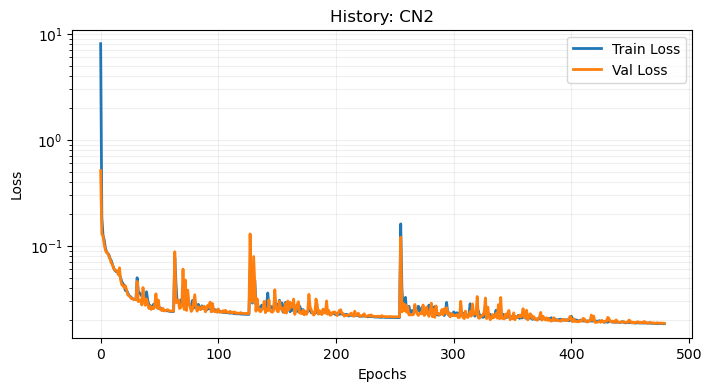

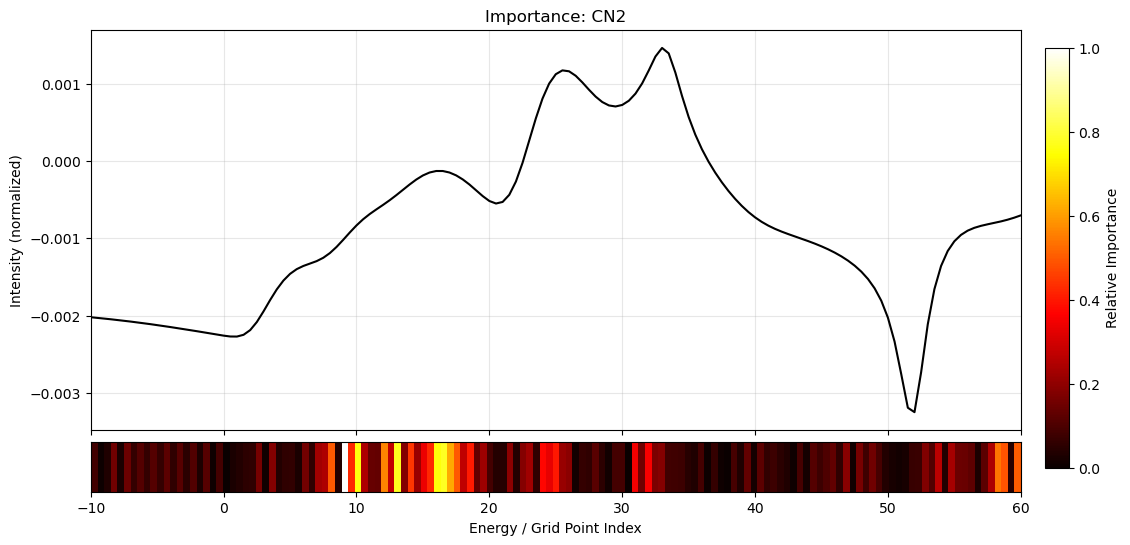

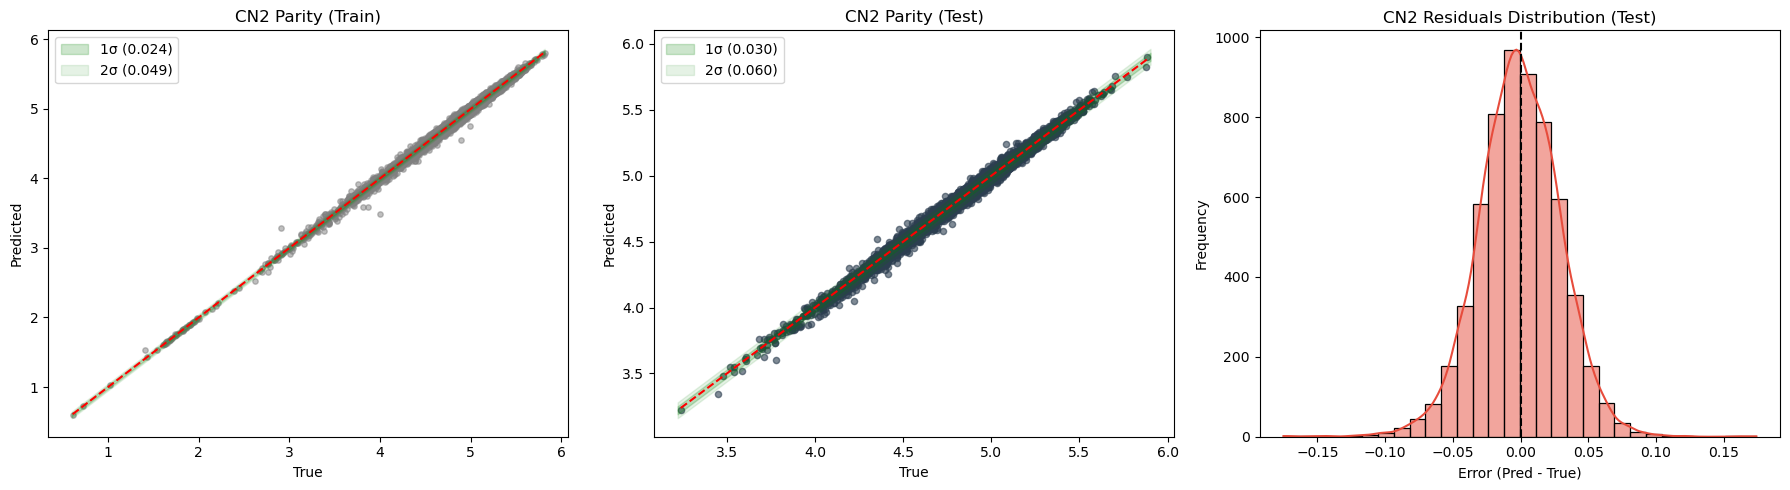


🚀 Моделирование CN3...


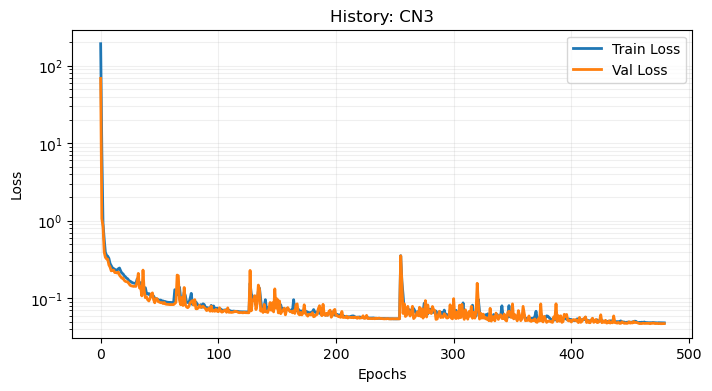

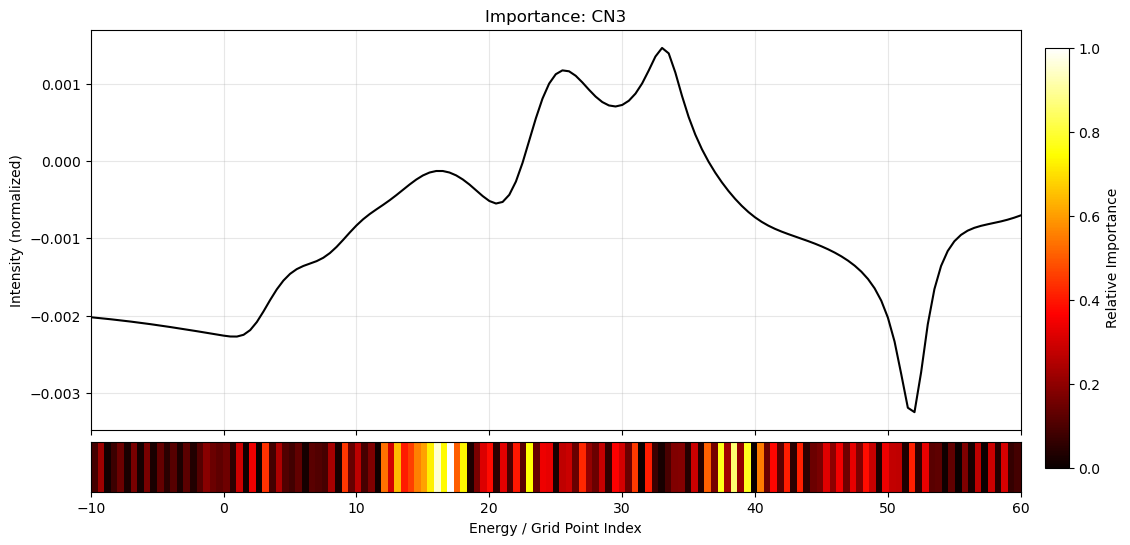

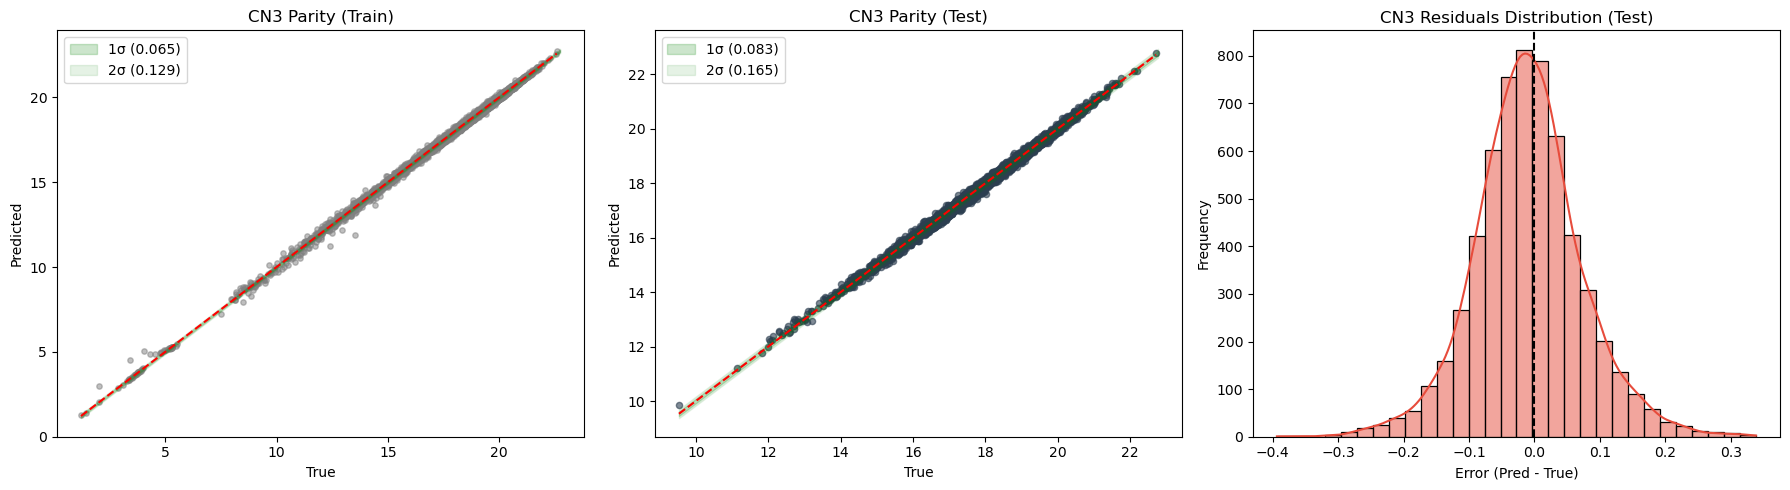


🚀 Моделирование CN4...


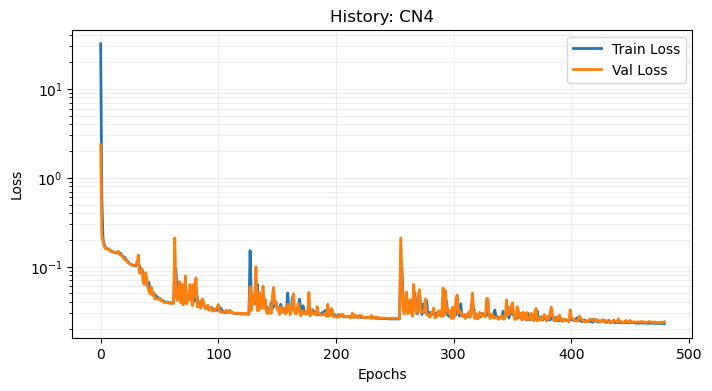

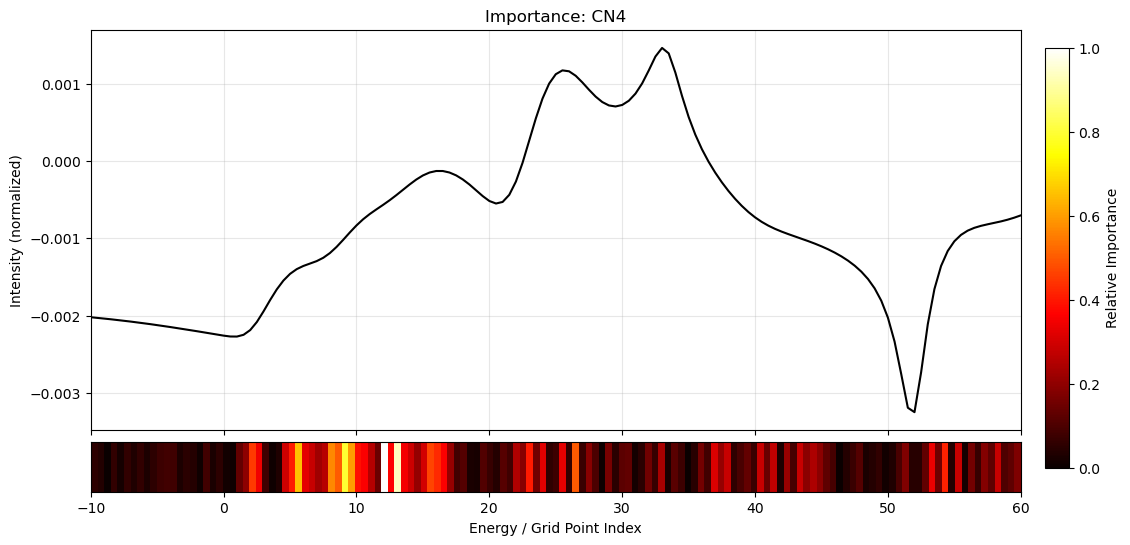

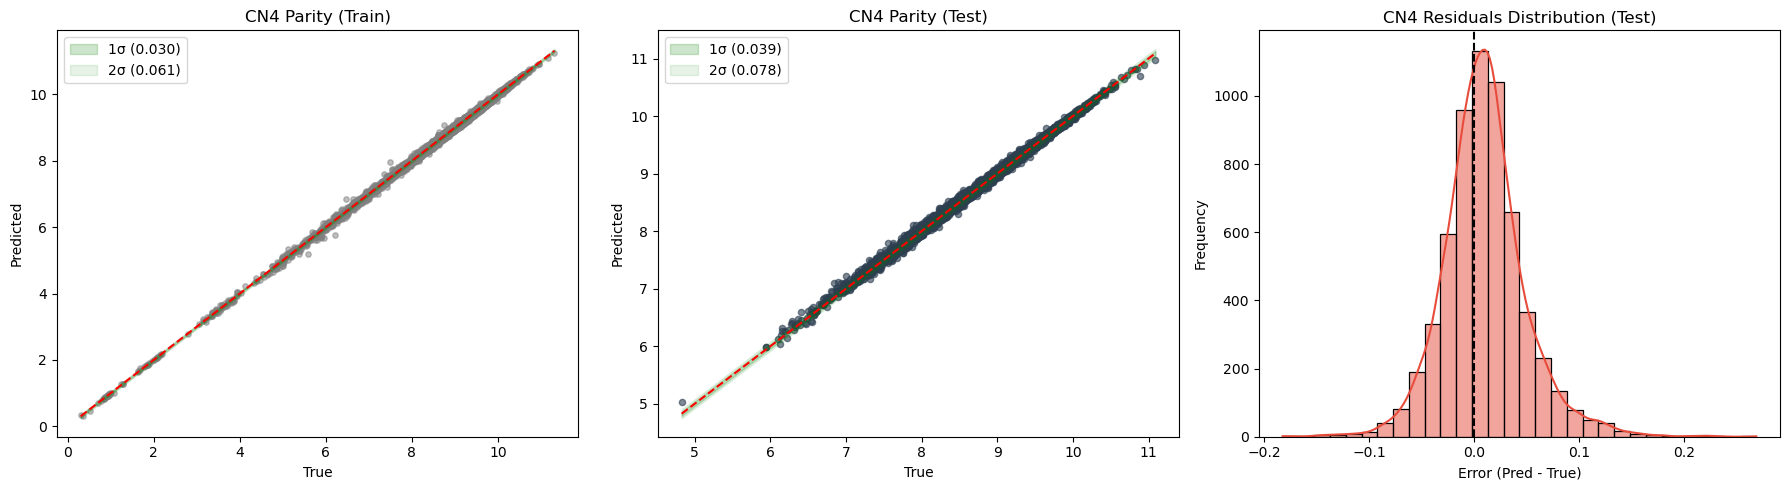


🚀 Моделирование CN5...


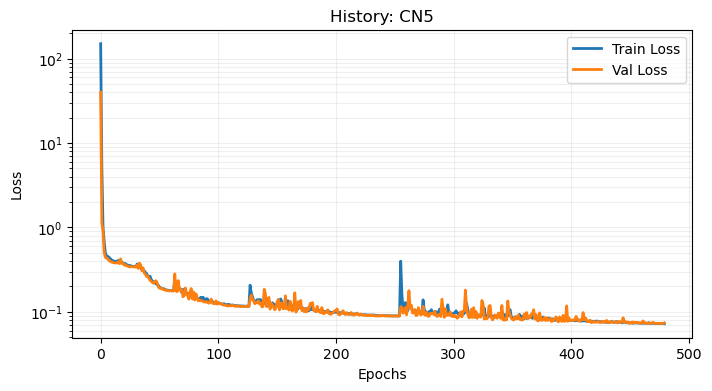

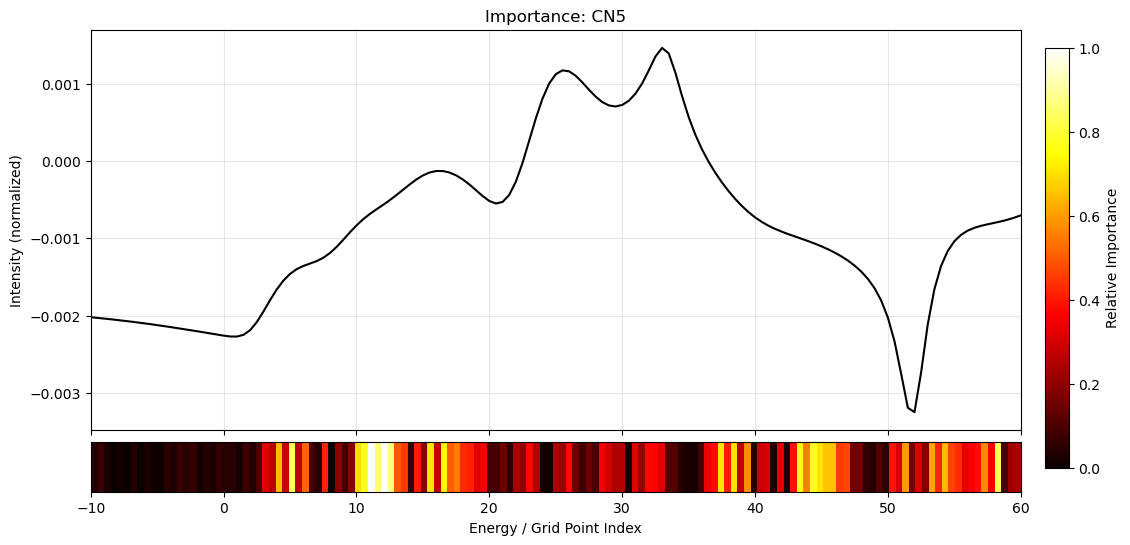

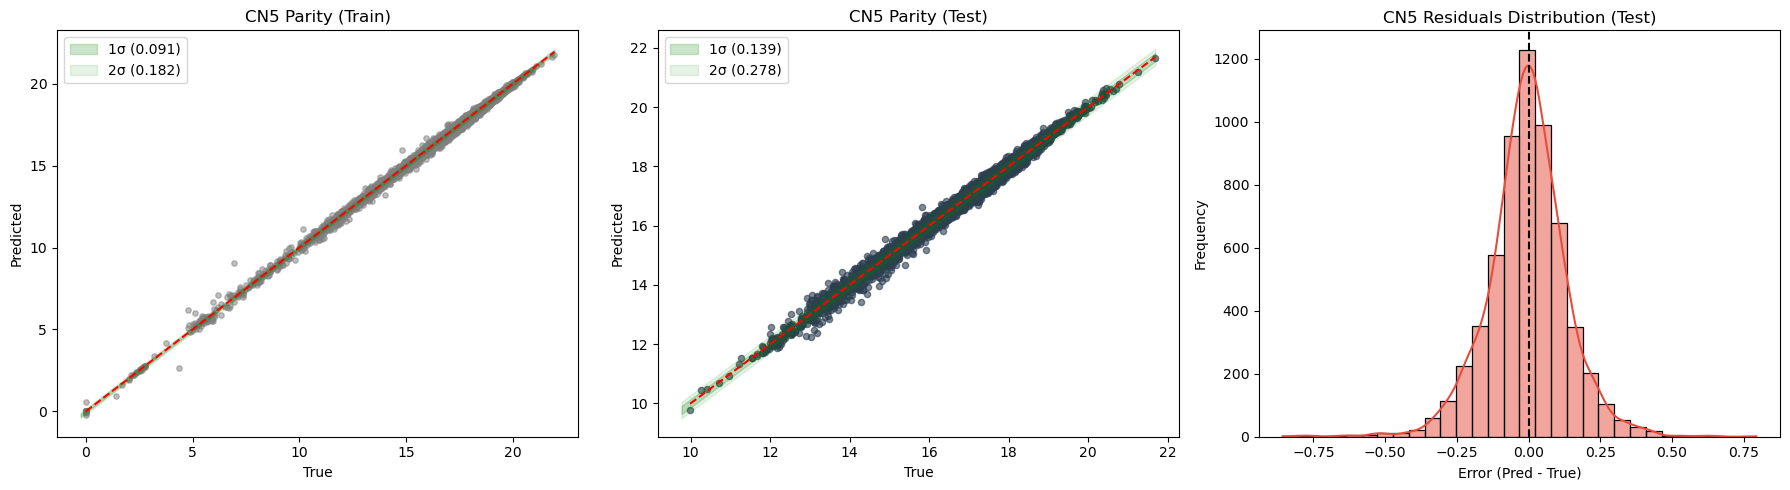


🚀 Моделирование CN6...


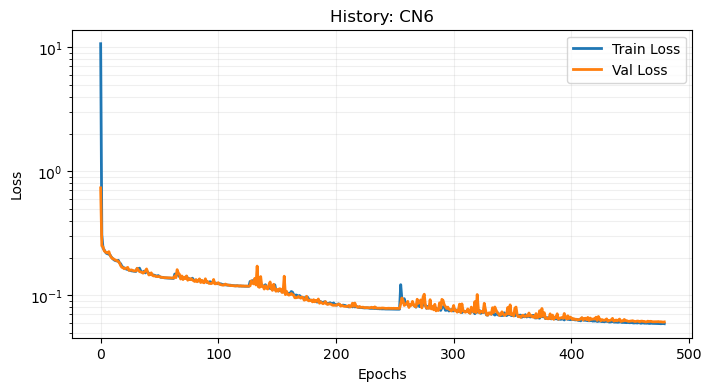

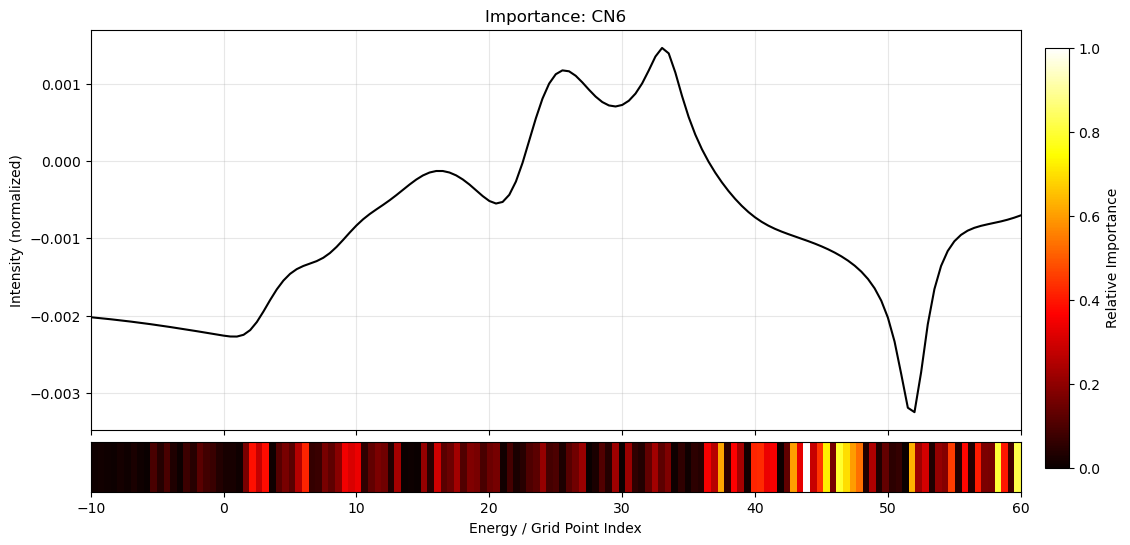

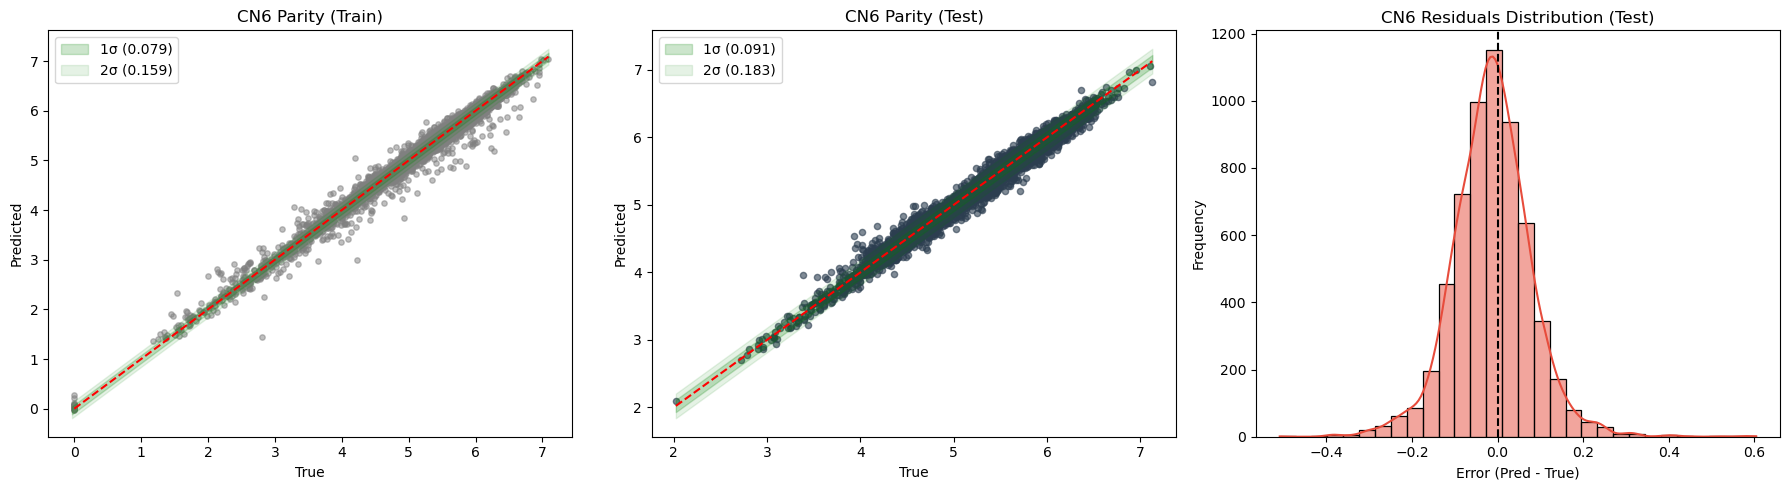


🚀 Моделирование CN7...


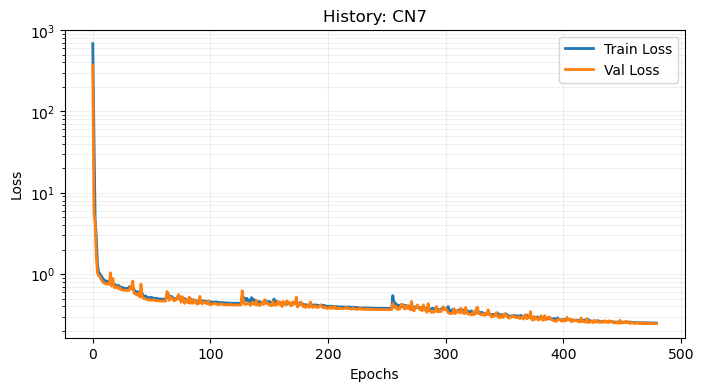

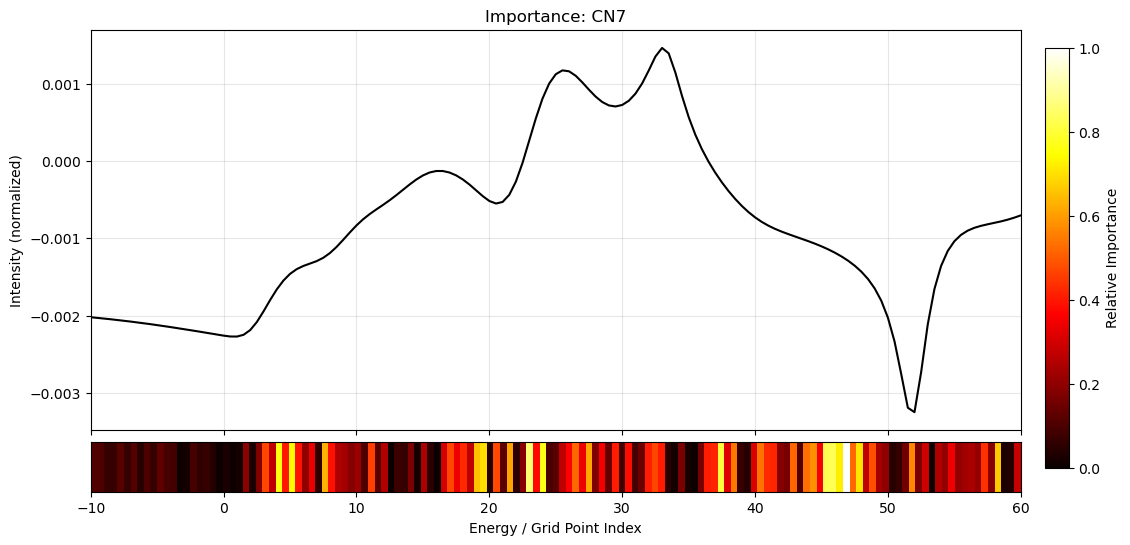

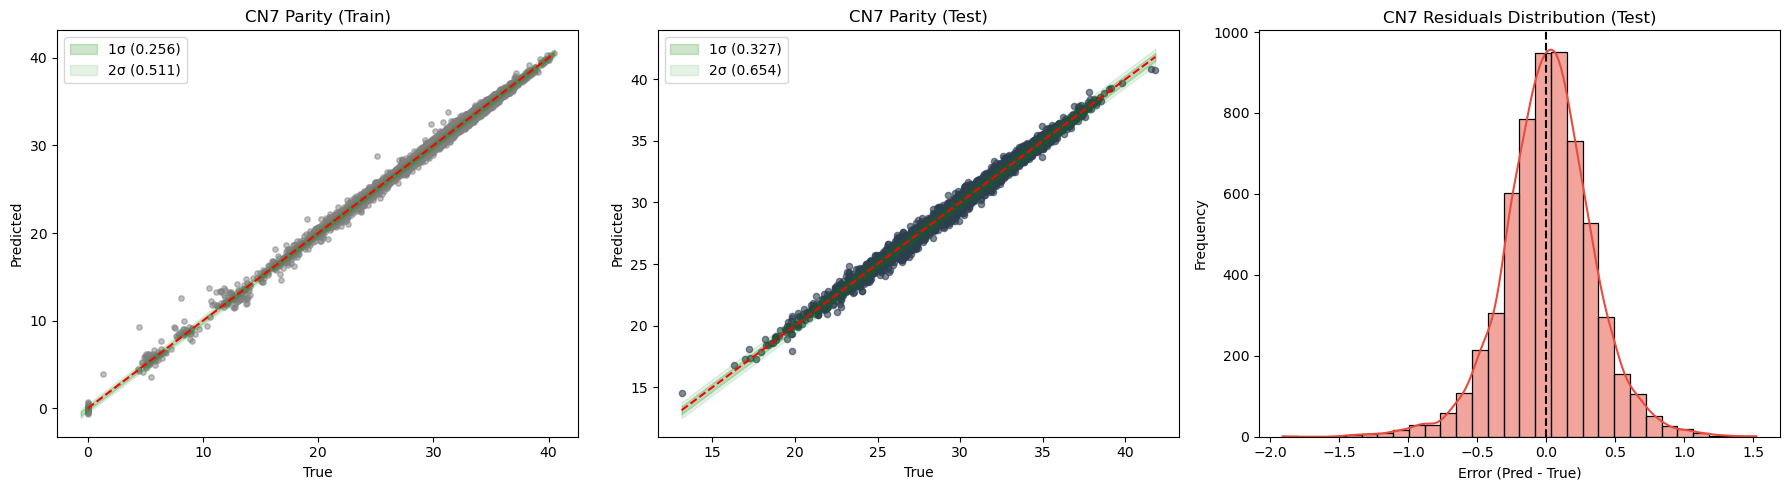


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9981 0.9993 0.9993 0.0166 0.0106 0.0104
CN2    0.9915 0.9953 0.9957 0.0235 0.0177 0.0180
CN3    0.9965 0.9984 0.9985 0.0634 0.0437 0.0430
CN4    0.9968 0.9987 0.9986 0.0296 0.0218 0.0223
CN5    0.9917 0.9975 0.9976 0.1023 0.0637 0.0646
CN6    0.9786 0.9850 0.9825 0.0693 0.0525 0.0531
CN7    0.9908 0.9957 0.9962 0.2473 0.1831 0.1823
CPU times: total: 34min 34s
Wall time: 34min 5s


In [9]:
%%time
save_root = Path('../processed_data/Results/Lauvian_2B/CNN/')  
model = XANES_CNN(in_dim=IN_DIM)
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
nn_wrapper = TorchWrapper(model=model,params=params)
pipeline_nn = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=nn_wrapper, e_grid=E_GRID)
pipeline_nn.run(paths=paths_Lauvian, save_root=save_root)